# 02 · Feature analysis and leakage-safe preprocessing

# Part A · Rossmann daily store sales

In [1]:
import json, warnings, os, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from scipy import stats
from IPython.display import Image, display

SEED = 2026
PREPROCESS_N_JOBS = 4  # fixed number of parallel threads
rng = np.random.default_rng(SEED)
pd.set_option(
    "display.max_rows",
    None,
    "display.max_columns",
    None,
    "display.max_colwidth",
    None,
    "display.width",
    220,
    "display.float_format",
    lambda v: f"{0.0 if abs(v)<0.00005 else v:,.4f}",
)

ROOT = Path("..").resolve()
RAW = ROOT / "dataset" / "raw"
INTERIM, PROCESSED, SPLITS = ROOT / "outputs" / "data" / "interim", ROOT / "outputs" / "data" / "processed", ROOT / "outputs" / "data" / "splits"
TABLES, FIGURES, MANIFESTS, CONFIGS = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures", ROOT / "outputs" / "manifests", ROOT / "outputs" / "configs"
for d in (INTERIM, PROCESSED, SPLITS, TABLES, FIGURES, MANIFESTS, CONFIGS):
    d.mkdir(parents=True, exist_ok=True)

_serif = "Times New Roman"
assert any(
    f.name == _serif for f in font_manager.fontManager.ttflist
), "Times New Roman is required"
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": [_serif, "Liberation Serif", "DejaVu Serif"],
        "font.size": 18,
        "axes.labelsize": 18,
        "axes.titlesize": 20,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "axes.unicode_minus": True,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "mathtext.sf": "Times New Roman",
        "mathtext.tt": "Times New Roman",
        "mathtext.cal": "Times New Roman",
        "mathtext.default": "regular",
        "mathtext.fallback": None,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
PALETTE = [
    "#0072B2",
    "#E69F00",
    "#009E73",
    "#D55E00",
    "#CC79A7",
    "#56B4E9",
    "#000000",
]  # Okabe–Ito, colour-blind safe

RUN_ID = "NB02_" + pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
TABLES = ROOT / "outputs" / "tables" / RUN_ID
FIGURES = ROOT / "outputs" / "figures" / "png" / RUN_ID
PDF_FIGURES = ROOT / "outputs" / "figures" / "pdf" / RUN_ID
for folder in (TABLES, FIGURES, PDF_FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

FIGURE_PARTS = {}


def save_fig(fig, name):
    """Save a figure as PNG (350 and 600 dpi) and PDF after checking the font and the 18–20 pt text size.
    Wide multi-panel masters are exported as separate panels, without shrinking text.
    """
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    text_items = [
        t
        for t in fig.findobj(match=matplotlib.text.Text)
        if t.get_visible() and t.get_text().strip()
    ]
    actual_fonts = {
        font_manager.FontProperties(
            fname=font_manager.findfont(
                t.get_fontproperties(), fallback_to_default=False
            )
        ).get_name()
        for t in text_items
    }
    assert actual_fonts == {_serif}, f"Unexpected figure font: {actual_fonts}"
    assert all(
        18 <= t.get_fontsize() <= 20 for t in text_items
    ), "Every visible master label must be 18–20 pt"
    master_bbox = fig.get_tightbbox(renderer).padded(0.08)
    axes = fig.axes
    has_colorbar = any(ax.get_label() == "<colorbar>" for ax in axes)
    separate = (
        not has_colorbar
        and master_bbox.width > 13.0
        and len(axes) > 1
        and all(
            abs(a.get_position().x0 - b.get_position().x0) > 0.01
            or abs(a.get_position().y0 - b.get_position().y0) > 0.01
            for i, a in enumerate(axes)
            for b in axes[i + 1 :]
        )
    )
    panels = (
        [
            (
                name + chr(97 + i),
                ax.get_tightbbox(renderer)
                .transformed(fig.dpi_scale_trans.inverted())
                .padded(0.08),
            )
            for i, ax in enumerate(axes)
        ]
        if separate
        else [(name, master_bbox)]
    )
    FIGURE_PARTS[name] = [key for key, _ in panels]
    for key, bbox in panels:
        fig.savefig(FIGURES / f"{key}.png", dpi=350, bbox_inches=bbox)
        fig.savefig(FIGURES / f"{key}_600dpi.png", dpi=600, bbox_inches=bbox)
        fig.savefig(PDF_FIGURES / f"{key}.pdf", bbox_inches=bbox)
    fig.clear()
    fig.set_size_inches(1, 1)
    fig.canvas.draw()
    plt.close(fig)
    gc.collect()


def show_fig(name, width=1000):
    from IPython.display import display

    for key in FIGURE_PARTS[name]:
        display(Image(filename=str(FIGURES / f"{key}.png"), width=1000))


def tidy(df, note="n/a"):
    """Display copy of a table: missing cells are marked explicitly (not applicable / not available) instead of NaN; underflowed p-values are shown as bounds."""
    out = df.copy()
    for c in out.columns:
        if "p-value" in str(c) or str(c).startswith("p ") or str(c) == "p":
            out[c] = [
                (
                    "< 1e-300"
                    if (isinstance(v, float) and v == 0.0)
                    else (f"{v:.3g}" if isinstance(v, (float, np.floating)) else v)
                )
                for v in out[c]
            ]
    return out.astype(object).where(out.notna(), note)


def label_panels(axes, labels="abcdefghij"):
    """Letter each panel of a multi-panel canvas below its x-axis label: (a), (b), ... so that panels can be cited in the text."""
    for ax, l in zip(np.ravel(axes), labels):
        ax.set_xlabel((ax.get_xlabel() + "\n" if ax.get_xlabel() else "") + f"({l})")


def save_table(df, name, caption, index=True, float_format="%.4f"):
    clean = tidy(df)
    clean.to_csv(TABLES / f"{name}.csv", index=index)
    (TABLES / f"{name}.tex").write_text(
        clean.to_latex(
            index=index,
            caption=caption,
            label=f"tab:{name}",
            float_format=lambda v: (
                (float_format % (0.0 if float(float_format % v) == 0 else v))
                if isinstance(float_format, str)
                else float_format(v)
            ),
            escape=True,
        )
    )
    return tidy(df)


design = json.loads((CONFIGS / "study_design.json").read_text())
LAG = design["label_lag_days"]
ross = pd.read_parquet(INTERIM / "rossmann_merged.parquet")
print(
    f"rows {len(ross):,} | stores {ross['Store'].nunique()} | label lag {LAG} d | partitions {sorted(ross['partition'].unique())}"
)


rows 1,017,209 | stores 1115 | label lag 7 d | partitions ['external_history', 'external_test', 'test_locked', 'train', 'valid']


## 1. Causal feature construction

Every lagged statistic of the target for day $t$ uses only days $\le t-7$; closed days are missing values, not zeros.

In [2]:
ross = ross.sort_values(["Store", "Date"]).reset_index(drop=True)
y_log = np.log(ross["Sales"].where(ross["retained"]))  # NaN on closed / zero-sales days
wide_y = y_log.groupby([ross["Date"], ross["Store"]]).first().unstack("Store")
wide_c = (
    ross["Customers"]
    .where(ross["retained"])
    .astype(float)
    .groupby([ross["Date"], ross["Store"]])
    .first()
    .unstack("Store")
)
full_idx = pd.date_range(ross["Date"].min(), ross["Date"].max(), freq="D")
wide_y, wide_c = wide_y.reindex(full_idx), wide_c.reindex(full_idx)
wide_promo = (
    ross["Promo"]
    .groupby([ross["Date"], ross["Store"]])
    .first()
    .unstack("Store")
    .reindex(full_idx)
)


def melt(wide, name):
    s = wide.stack(future_stack=True)
    s.index.names = ["Date", "Store"]
    return s.rename(name)


feats = {}
sh = wide_y.shift(LAG)  # last usable observation is t-7
for k in (7, 14, 21, 28, 364):
    feats[f"lag_{k}"] = melt(wide_y.shift(k), f"lag_{k}")
for w in (7, 28, 91):
    r = sh.rolling(w, min_periods=max(2, w // 4))
    feats[f"rmean_{w}"] = melt(r.mean(), f"rmean_{w}")
    feats[f"rstd_{w}"] = melt(r.std(), f"rstd_{w}")
    if w > 7:
        feats[f"rmin_{w}"] = melt(r.min(), f"rmin_{w}")
        feats[f"rmax_{w}"] = melt(r.max(), f"rmax_{w}")
feats["expanding_mean"] = melt(sh.expanding(min_periods=14).mean(), "expanding_mean")
# same weekday over the last 8 weeks: lags 7, 14, ..., 56
dow_lags = [wide_y.shift(7 * j) for j in range(1, 9)]
dow_count = sum(x.notna().astype(int) for x in dow_lags)
dow_mean = sum(x.fillna(0) for x in dow_lags) / dow_count.replace(0, np.nan)
feats["same_dow_mean_8w"] = melt(dow_mean.where(dow_count >= 3), "same_dow_mean_8w")
# historical mean under promo and without promo, ending at t-7 (28-day window)
promo_sh = wide_promo.shift(LAG)
feats["rmean_28_promo"] = melt(
    sh.where(promo_sh == 1).rolling(28, min_periods=3).mean(), "rmean_28_promo"
)
feats["rmean_28_nopromo"] = melt(
    sh.where(promo_sh == 0).rolling(28, min_periods=3).mean(), "rmean_28_nopromo"
)
cs = wide_c.shift(LAG)
feats["cust_rmean_7"] = melt(cs.rolling(7, min_periods=2).mean(), "cust_rmean_7")
feats["cust_rmean_28"] = melt(cs.rolling(28, min_periods=7).mean(), "cust_rmean_28")
feats["sales_per_cust_28"] = melt(
    (np.exp(sh) / cs).rolling(28, min_periods=7).mean(), "sales_per_cust_28"
)
# Store calendar: opening days and promotion runs are planned information, known at forecast time (the source supplies Open and Promo
# for every date, including the locked period). Closed days outside the data gap count as closed.
wide_open = ross["Open"].groupby([ross["Date"], ross["Store"]]).first().unstack("Store").reindex(full_idx).fillna(0)


def run_length(mat, forward=False):
    """Consecutive days with value 1 up to and including each day (forward=True: from each day until the next 0)."""
    a = (mat.to_numpy() == 1).astype(int)
    out = np.zeros_like(a)
    run = np.zeros(a.shape[1], int)
    for i in range(a.shape[0] - 1, -1, -1) if forward else range(a.shape[0]):
        run = np.where(a[i] == 1, run + 1, 0)
        out[i] = run
    return pd.DataFrame(out, index=mat.index, columns=mat.columns)


feats["open_run"] = melt(run_length(wide_open).clip(upper=30), "open_run")
feats["open_until"] = melt(run_length(wide_open, forward=True).clip(upper=14), "open_until")
feats["closed_yesterday"] = melt((wide_open.shift(1).fillna(0) == 0).astype(float), "closed_yesterday")
feats["closed_tomorrow"] = melt((wide_open.shift(-1).fillna(0) == 0).astype(float), "closed_tomorrow")
closed = (wide_open.to_numpy() == 0).astype(int)
last_len, gap, spell = np.zeros(closed.shape[1]), np.zeros(closed.shape[1]), np.zeros(closed.shape, float)
for i in range(closed.shape[0]):
    last_len = np.where((closed[i] == 0) & (gap > 0), gap, last_len)
    gap = np.where(closed[i] == 1, gap + 1, 0.0)
    spell[i] = last_len
feats["last_closure_len"] = melt(pd.DataFrame(spell, index=full_idx, columns=wide_open.columns).clip(upper=60), "last_closure_len")
wp = wide_promo.fillna(0)
feats["promo_run"] = melt(run_length(wp).clip(upper=10), "promo_run")
feats["promo_yesterday"] = melt((wp.shift(1).fillna(0) == 1).astype(float), "promo_yesterday")
feats["promo_tomorrow"] = melt((wp.shift(-1).fillna(0) == 1).astype(float), "promo_tomorrow")
# Year-over-year history with the 7-day lag: last year's local level (days t-378 .. t-350) and last year's deviation on this date
yoy_level = wide_y.shift(350).rolling(29, min_periods=3).mean()
feats["yoy_level"] = melt(yoy_level, "yoy_level")
feats["yoy_ratio"] = melt(wide_y.shift(364) - yoy_level, "yoy_ratio")
# Same weekday and same promotion status over the last 12 weeks (lags 7, 14, ..., 84), promotion status matched to today's
same_lags = [wide_y.shift(7 * j).where(wide_promo.shift(7 * j) == wide_promo) for j in range(1, 13)]
same_count = sum(x.notna().astype(int) for x in same_lags)
feats["sdp_mean_12w"] = melt((sum(x.fillna(0) for x in same_lags) / same_count.replace(0, np.nan)).where(same_count >= 2), "sdp_mean_12w")
SCHEDULE = ["open_run", "open_until", "closed_yesterday", "closed_tomorrow", "last_closure_len", "promo_run", "promo_yesterday", "promo_tomorrow"]
hist = pd.concat(feats.values(), axis=1).reset_index()
df = ross.merge(hist, on=["Date", "Store"], how="left", validate="one_to_one")


In [3]:
d = df["Date"]
df["dow"] = d.dt.dayofweek + 1
df["day"] = d.dt.day
df["week"] = d.dt.isocalendar().week.astype(int)
df["month"] = d.dt.month
df["year"] = d.dt.year
df["doy"] = d.dt.dayofyear
df["month_pos"] = np.select(
    [df["day"] <= 10, df["day"] <= 20], [0, 1], 2
)  # beginning / middle / end of month
df["StateHoliday"] = df["StateHoliday"].astype(str).replace({"0.0": "0"})
df["state_holiday"] = (
    df["StateHoliday"].map({"0": 0, "a": 1, "b": 2, "c": 3}).fillna(0).astype(int)
)
df["school_holiday"] = df["SchoolHoliday"].astype(int)
df["promo"] = df["Promo"].astype(int)
# Promo2: active if the store participates, the date is after the start week and the month is in PromoInterval
month_abbr = {
    1: "Jan",
    2: "Feb",
    3: "Mar",
    4: "Apr",
    5: "May",
    6: "Jun",
    7: "Jul",
    8: "Aug",
    9: "Sept",
    10: "Oct",
    11: "Nov",
    12: "Dec",
}
p2_start = pd.to_datetime(
    df["Promo2SinceYear"].fillna(2100).astype(int).astype(str)
    + "-W"
    + df["Promo2SinceWeek"].fillna(1).astype(int).astype(str).str.zfill(2)
    + "-1",
    format="%G-W%V-%u",
)
in_interval = [
    str(m) in str(pi).split(",")
    for m, pi in zip(df["month"].map(month_abbr), df["PromoInterval"].fillna(""))
]
df["promo2_active"] = (
    (df["Promo2"] == 1) & (d >= p2_start) & pd.Series(in_interval, index=df.index)
).astype(int)
df["promo2_days"] = np.where(df["Promo2"] == 1, (d - p2_start).dt.days.clip(lower=0), 0)
comp_open = pd.to_datetime(
    dict(
        year=df["CompetitionOpenSinceYear"].fillna(1900).astype(int),
        month=df["CompetitionOpenSinceMonth"].fillna(1).astype(int),
        day=1,
    )
)
df["comp_months"] = np.where(
    df["CompetitionOpenSinceYear"].notna(),
    ((d - comp_open).dt.days / 30.44).clip(lower=0),
    np.nan,
)
df["comp_recent"] = ((df["comp_months"] >= 0) & (df["comp_months"] <= 12)).astype(int)
df["log_comp_dist"] = np.log1p(df["CompetitionDistance"])
df["store_type"] = df["StoreType"].map({"a": 0, "b": 1, "c": 2, "d": 3}).astype(int)
df["assortment"] = df["Assortment"].map({"a": 0, "b": 1, "c": 2}).astype(int)
# holiday proximity: days to next / since last state holiday (schedule information, known in advance)
hol_dates = np.sort(df.loc[df["state_holiday"] > 0, "Date"].unique())
all_dates = pd.Series(full_idx)
nxt = np.searchsorted(hol_dates, all_dates.values, side="left")
prv = np.searchsorted(hol_dates, all_dates.values, side="right") - 1
days_to_next = np.where(
    nxt < len(hol_dates),
    (hol_dates[np.minimum(nxt, len(hol_dates) - 1)] - all_dates.values)
    / np.timedelta64(1, "D"),
    400,
)
days_since_prev = np.where(
    prv >= 0,
    (all_dates.values - hol_dates[np.maximum(prv, 0)]) / np.timedelta64(1, "D"),
    400,
)
prox = pd.DataFrame(
    {
        "Date": full_idx,
        "days_to_holiday": np.minimum(days_to_next, 60),
        "days_since_holiday": np.minimum(days_since_prev, 60),
    }
)
df = df.merge(prox, on="Date", how="left")
df["log_sales"] = np.log(df["Sales"].where(df["retained"]))

# Movable carnival calendar (Rosenmontag = Easter - 48 days). The store sensitivity of year y uses only earlier years,
# whose +/-28-day reference windows are complete long before the first forecast date of year y.
from dateutil.easter import easter

CARN_OFFSETS = [-4, -3, -2, 0, 1]  # Altweiber, Friday, Saturday, Rosenmontag, carnival Tuesday
ROSENMONTAG = {y: pd.Timestamp(easter(y)) - pd.Timedelta(days=48) for y in (2013, 2014, 2015)}
offset = (df["Date"] - df["Date"].dt.year.map(ROSENMONTAG)).dt.days
df["carn_code"] = offset.map({o: i + 1 for i, o in enumerate(CARN_OFFSETS)}).fillna(0).astype(int)
_kept = df.loc[df["retained"] & (df["Date"] < "2015-01-01"), ["Store", "Date", "Sales", "promo", "carn_code"]]
_effects = []
for y in (2013, 2014):
    for o in CARN_OFFSETS:
        t = ROSENMONTAG[y] + pd.Timedelta(days=o)
        normal = _kept[(_kept["Date"].dt.year == y) & ((_kept["Date"] - t).abs() <= pd.Timedelta(days=28))
                       & (_kept["Date"].dt.dayofweek == t.dayofweek) & (_kept["carn_code"] == 0)]
        ref = normal.groupby(["Store", "promo"])["Sales"].median().rename("reference").reset_index()
        e = _kept[_kept["Date"] == t].merge(ref, on=["Store", "promo"])
        e["effect"], e["offset"], e["year"] = np.log(e["Sales"] / e["reference"]), o, y
        _effects.append(e[["Store", "year", "offset", "effect"]])
CARN_EFFECTS = pd.concat(_effects, ignore_index=True)
CARN_SHRINK = 1.0  # one pseudo-observation of the chain-wide mean per offset; fixed a priori
df["carn_eff"] = 0.0
for y, past in {2014: [2013], 2015: [2013, 2014]}.items():
    for o in CARN_OFFSETS:
        e = CARN_EFFECTS[CARN_EFFECTS["year"].isin(past) & (CARN_EFFECTS["offset"] == o)]
        g = e.groupby("Store")["effect"].agg(["sum", "size"])
        shrunk = (g["sum"] + CARN_SHRINK * e["effect"].mean()) / (g["size"] + CARN_SHRINK)
        i = df["Date"] == ROSENMONTAG[y] + pd.Timedelta(days=o)
        df.loc[i, "carn_eff"] = df.loc[i, "Store"].map(shrunk).fillna(e["effect"].mean()).values
assert df.loc[df["Date"].dt.year == 2013, "carn_eff"].eq(0).all(), "2013 has no earlier year"

GROUPS = {
    "G1_calendar": ["dow", "day", "week", "month", "year", "doy", "month_pos"],
    "G2_schedule": [
        "promo",
        "state_holiday",
        "school_holiday",
        "promo2_active",
        "promo2_days",
        "comp_months",
        "comp_recent",
        "days_to_holiday",
        "days_since_holiday",
    ],
    "G3_store": ["store_type", "assortment", "log_comp_dist"],
    "G4_history": [c for c in feats if not c.startswith(("cust_", "sales_per")) and c not in SCHEDULE],
    "G5_customers": ["cust_rmean_7", "cust_rmean_28", "sales_per_cust_28"],
    "G6_movable_calendar": ["carn_code", "carn_eff"],
    "G7_schedule": SCHEDULE,
}
FEATURES = sum(GROUPS.values(), [])
CATEGORICAL = ["dow", "month_pos", "state_holiday", "store_type", "assortment", "carn_code"]
NUMERIC = [f for f in FEATURES if f not in CATEGORICAL]
group_of = {f: g for g, cols in GROUPS.items() for f in cols}
print(
    f"{len(FEATURES)} features: "
    + ", ".join(f"{g} ({len(c)})" for g, c in GROUPS.items())
)


54 features: G1_calendar (7), G2_schedule (9), G3_store (3), G4_history (22), G5_customers (3), G6_movable_calendar (2), G7_schedule (8)


### Movable-calendar group (carnival days)

In [4]:
carn_table = (CARN_EFFECTS.groupby(["year", "offset"])["effect"].agg(stores="size", median_log_effect="median", sd_log_effect="std",
    share_below_0_6=lambda e: float((np.exp(e) < 0.6).mean())).reset_index())
_p = CARN_EFFECTS.pivot_table(index=["Store", "offset"], columns="year", values="effect").dropna()
carn_rep = _p.groupby("offset").apply(lambda g: pd.Series({"paired stores": len(g), "Spearman 2013 vs 2014": g[2013].corr(g[2014], method="spearman")})).reset_index()
print("Carnival response, completed training years only"); display(carn_table); display(carn_rep)
assert (df.loc[df["Date"] >= "2015-05-01", "carn_code"] == 0).all() and (df.loc[df["Date"] >= "2015-05-01", "carn_eff"] == 0).all(), "No carnival day inside the test window"


Carnival response, completed training years only


,year,offset,stores,median_log_effect,sd_log_effect,share_below_0_6
0,2013,-4,1107,-0.0029,0.2141,0.0461
1,2013,-3,1109,0.0046,0.0881,0.0000
2,2013,-2,1109,0.0153,0.1253,0.0099
3,2013,0,1076,0.0407,0.3781,0.1273
4,2013,1,1106,0.0237,0.2486,0.0570
5,2014,-4,1113,0.0065,0.2023,0.0422
6,2014,-3,1114,0.1074,0.1010,0.0000
7,2014,-2,1115,0.1247,0.1245,0.0072
8,2014,0,1084,0.0286,0.3707,0.1208
9,2014,1,1112,0.0343,0.2185,0.0459


,offset,paired stores,Spearman 2013 vs 2014
0,-4,"1,106.0000",0.3323
1,-3,"1,108.0000",0.1793
2,-2,"1,109.0000",0.2306
3,0,"1,075.0000",0.5333
4,1,"1,106.0000",0.6679


## 2. Leakage checks and covariate shift

In [5]:
trn = df[
    df["retained"]
    & (df["partition"] == "train")
    & (df["Date"] <= design["fit_label_cutoff"])
]
val = df[
    df["retained"]
    & (df["partition"] == "valid")
    & (df["Date"] <= design["selection_label_cutoff"])
]
forbidden = {
    "Customers",
    "Sales",
    "Open",
    "log_sales",
    "row_id",
    "partition",
    "retained",
    "Date",
}
assert not forbidden & set(
    FEATURES
), "contemporaneous columns leaked into the feature list"
sample = trn.sample(150_000, random_state=SEED)
lag0 = {
    "rmean_7_lag0": melt(wide_y.rolling(7, min_periods=2).mean(), "x"),
    "rmean_28_lag0": melt(wide_y.rolling(28, min_periods=7).mean(), "x"),
}
lag0 = pd.concat(lag0.values(), axis=1, keys=lag0.keys()).reset_index()
lag0.columns = ["Date", "Store", "rmean_7_lag0", "rmean_28_lag0"]
probe = sample.merge(lag0, on=["Date", "Store"], how="left")
shift_test = pd.DataFrame(
    {
        "lag 0 (forbidden diagnostic)": [
            probe[["log_sales", "rmean_7_lag0"]].corr("spearman").iloc[0, 1],
            probe[["log_sales", "rmean_28_lag0"]].corr("spearman").iloc[0, 1],
        ],
        f"lag {LAG} (used)": [
            probe[["log_sales", "rmean_7"]].corr("spearman").iloc[0, 1],
            probe[["log_sales", "rmean_28"]].corr("spearman").iloc[0, 1],
        ],
    },
    index=["rolling mean 7 d", "rolling mean 28 d"],
)
shift_test["difference"] = shift_test.iloc[:, 0] - shift_test.iloc[:, 1]
save_table(
    shift_test,
    "tab2_1_temporal_shift_test",
    "Spearman correlation with log sales of rolling means computed with lag 0 (includes the forecast day; forbidden) versus the 7-day lag used in the study.",
)
# Boundary test on observed development histories: replace every label that is not yet available.
causal_checks = []
for forecast_date in (pd.Timestamp("2014-04-01"), pd.Timestamp("2015-01-01")):
    base = wide_y.loc[: design["selection_label_cutoff"]].iloc[:, :5].copy()
    changed = base.copy()
    changed.loc[changed.index > forecast_date - pd.Timedelta(days=LAG)] = 999.0
    for window in (7, 28, 91):
        before = (
            base.shift(LAG)
            .rolling(window, min_periods=max(2, window // 4))
            .mean()
            .loc[forecast_date]
        )
        after = (
            changed.shift(LAG)
            .rolling(window, min_periods=max(2, window // 4))
            .mean()
            .loc[forecast_date]
        )
        np.testing.assert_allclose(before, after, equal_nan=True)
        causal_checks.append(
            {"date": str(forecast_date.date()), "window": window, "unchanged": True}
        )
display(tidy(shift_test))


,lag 0 (forbidden diagnostic),lag 7 (used),difference
rolling mean 7 d,0.8006,0.6547,0.1459
rolling mean 28 d,0.7678,0.7460,0.0217


In [6]:
mt, mv = trn[NUMERIC].mean(), val[NUMERIC].mean()
sp = np.sqrt((trn[NUMERIC].var() + val[NUMERIC].var()) / 2).replace(0, np.nan)
smd = pd.DataFrame(
    {
        "group": [group_of[f] for f in NUMERIC],
        "mean train": mt,
        "mean valid": mv,
        "SMD (valid − train)": (mv - mt) / sp,
        "missing % train": 100 * trn[NUMERIC].isna().mean(),
        "missing % valid": 100 * val[NUMERIC].isna().mean(),
    }
)
smd["|SMD|"] = smd["SMD (valid − train)"].abs()
smd = smd.sort_values("|SMD|", ascending=False).drop(columns="|SMD|")
save_table(
    smd,
    "tab2_2_covariate_shift_smd",
    "Covariate shift between the training and validation periods: standardised mean difference of every numeric feature (|SMD| > 0.5 is conventionally large) and missingness per period.",
    float_format="%.3f",
)


,group,mean train,mean valid,SMD (valid − train),missing % train,missing % valid
year,G1_calendar,"2,013.4756","2,015.0000",4.3168,0.0000,0.0000
month,G1_calendar,6.3636,2.4055,-1.5579,0.0000,0.0000
doy,G1_calendar,178.0408,57.6605,-1.5573,0.0000,0.0000
week,G1_calendar,25.9624,9.1596,-1.5221,0.0000,0.0000
promo2_days,G2_schedule,340.5350,547.8953,0.3408,0.0000,0.0000
days_to_holiday,G2_schedule,27.4410,33.4367,0.2848,0.0000,0.0000
comp_recent,G2_schedule,0.1751,0.0863,-0.2656,0.0000,0.0000
days_since_holiday,G2_schedule,27.3219,32.4109,0.2362,0.0000,0.0000
rmax_91,G4_history,9.3203,9.3958,0.2232,4.6847,4.6194
rmean_91,G4_history,8.7369,8.8061,0.2093,4.6847,4.6194


In [7]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

adv = pd.concat(
    [
        trn.sample(100_000, random_state=SEED).assign(is_valid=0),
        val.sample(min(100_000, len(val)), random_state=SEED).assign(is_valid=1),
    ]
)
adv_feats = [
    f for f in FEATURES if f not in ("year", "doy", "week", "month", "day")
]  # calendar position trivially separates periods
Xa, ya = adv[adv_feats], adv["is_valid"]
idx = rng.permutation(len(adv))
cut = int(0.7 * len(adv))
clf = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=SEED,
    n_jobs=PREPROCESS_N_JOBS,
    verbose=-1,
)
clf.fit(Xa.iloc[idx[:cut]], ya.iloc[idx[:cut]])
auc = roc_auc_score(ya.iloc[idx[cut:]], clf.predict_proba(Xa.iloc[idx[cut:]])[:, 1])
imp = pd.Series(clf.booster_.feature_importance("gain"), index=adv_feats).sort_values(
    ascending=False
)
adv_tab = (imp / imp.sum()).rename("share of gain").to_frame()
adv_tab.loc["— adversarial AUC, all non-calendar features —"] = auc
# second probe: additionally drop the features whose *availability* (not value) differs between periods
adv_feats2 = [
    f
    for f in adv_feats
    if f
    not in (
        "lag_364",
        "days_to_holiday",
        "days_since_holiday",
        "promo2_days",
        "comp_months",
    )
]
clf2 = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=SEED,
    n_jobs=PREPROCESS_N_JOBS,
    verbose=-1,
)
clf2.fit(Xa.iloc[idx[:cut]][adv_feats2], ya.iloc[idx[:cut]])
auc2 = roc_auc_score(
    ya.iloc[idx[cut:]], clf2.predict_proba(Xa.iloc[idx[cut:]][adv_feats2])[:, 1]
)
adv_tab.loc[
    "— adversarial AUC, also without lag_364, holiday proximity, promo2/competition age —"
] = auc2
save_table(
    adv_tab,
    "tab2_3_adversarial_validation",
    "Adversarial validation between train and validation periods: AUC and all non-calendar feature importances.",
)


,share of gain
yoy_level,0.3397
days_to_holiday,0.1710
days_since_holiday,0.1688
month_pos,0.0613
yoy_ratio,0.0285
promo2_days,0.0264
rmean_91,0.0249
promo,0.0193
comp_months,0.0146
promo_yesterday,0.0132


## 3. Predictive signal of the features

In [8]:
from sklearn.feature_selection import mutual_info_regression

num = sample[FEATURES].copy()
spear = num.corrwith(sample["log_sales"], method="spearman")
mi_X = num.fillna(num.median())
mi = pd.Series(
    mutual_info_regression(mi_X, sample["log_sales"], random_state=SEED, n_neighbors=5),
    index=FEATURES,
)
signal = pd.DataFrame(
    {
        "group": [group_of[f] for f in FEATURES],
        "spearman": spear,
        "mutual information (nats)": mi,
        "missing % (train)": 100 * trn[FEATURES].isna().mean(),
    }
).sort_values("mutual information (nats)", ascending=False)
save_table(
    signal,
    "tab2_4_feature_signal",
    "Univariate signal of every feature on a 150k-row training sample: Spearman correlation with log sales, mutual information, and share of missing values.",
)


,group,spearman,mutual information (nats),missing % (train)
sdp_mean_12w,G4_history,0.9134,0.9856,3.8304
lag_14,G4_history,0.8275,0.6660,5.2198
same_dow_mean_8w,G4_history,0.8039,0.5948,3.1521
lag_28,G4_history,0.7853,0.5627,7.0843
rmean_28,G4_history,0.7460,0.4496,2.1054
expanding_mean,G4_history,0.7433,0.4414,3.2918
rmean_28_nopromo,G4_history,0.7366,0.4399,1.4139
rmean_91,G4_history,0.7418,0.4306,4.6847
rmean_28_promo,G4_history,0.7166,0.4046,2.1173
rmin_28,G4_history,0.6750,0.3881,2.1054


## 4. Redundancy and multicollinearity

In [9]:
Z = (mi_X[NUMERIC] - mi_X[NUMERIC].mean()) / mi_X[NUMERIC].std().replace(0, 1)
R = np.corrcoef(Z.to_numpy(), rowvar=False)
try:
    vif = np.diag(np.linalg.inv(R))
except np.linalg.LinAlgError:
    vif = np.diag(np.linalg.pinv(R))
corr_abs = pd.DataFrame(np.abs(R), index=NUMERIC, columns=NUMERIC)
np.fill_diagonal(corr_abs.values, 0)
redund = pd.DataFrame(
    {
        "group": [group_of[f] for f in NUMERIC],
        "VIF": vif,
        "max |r| with another feature": corr_abs.max(axis=1),
        "most correlated feature": corr_abs.idxmax(axis=1),
    },
    index=NUMERIC,
)
redund = redund.sort_values("VIF", ascending=False)
cond = float(np.linalg.cond(Z.to_numpy()))
save_table(
    redund,
    "tab2_5_multicollinearity",
    f"Variance inflation factors and strongest pairwise Pearson correlation of every numeric feature (150k-row training sample, median-imputed and standardised); condition number of the standardised design matrix = {cond:,.0f}.",
    float_format="%.2f",
)


,group,VIF,max |r| with another feature,most correlated feature
doy,G1_calendar,"26,185.4295",0.9966,month
month,G1_calendar,"26,144.5360",0.9966,doy
rmean_28,G4_history,193.9481,0.9773,rmean_28_nopromo
day,G1_calendar,180.8386,0.1228,promo
cust_rmean_28,G5_customers,87.0244,0.9781,cust_rmean_7
cust_rmean_7,G5_customers,83.3731,0.9781,cust_rmean_28
rmean_28_promo,G4_history,61.7814,0.9652,rmean_28
rmean_91,G4_history,60.2557,0.9797,expanding_mean
rmean_28_nopromo,G4_history,57.9002,0.9773,rmean_28
same_dow_mean_8w,G4_history,48.6239,0.8901,sdp_mean_12w


condition number of the standardised numeric design matrix: 894


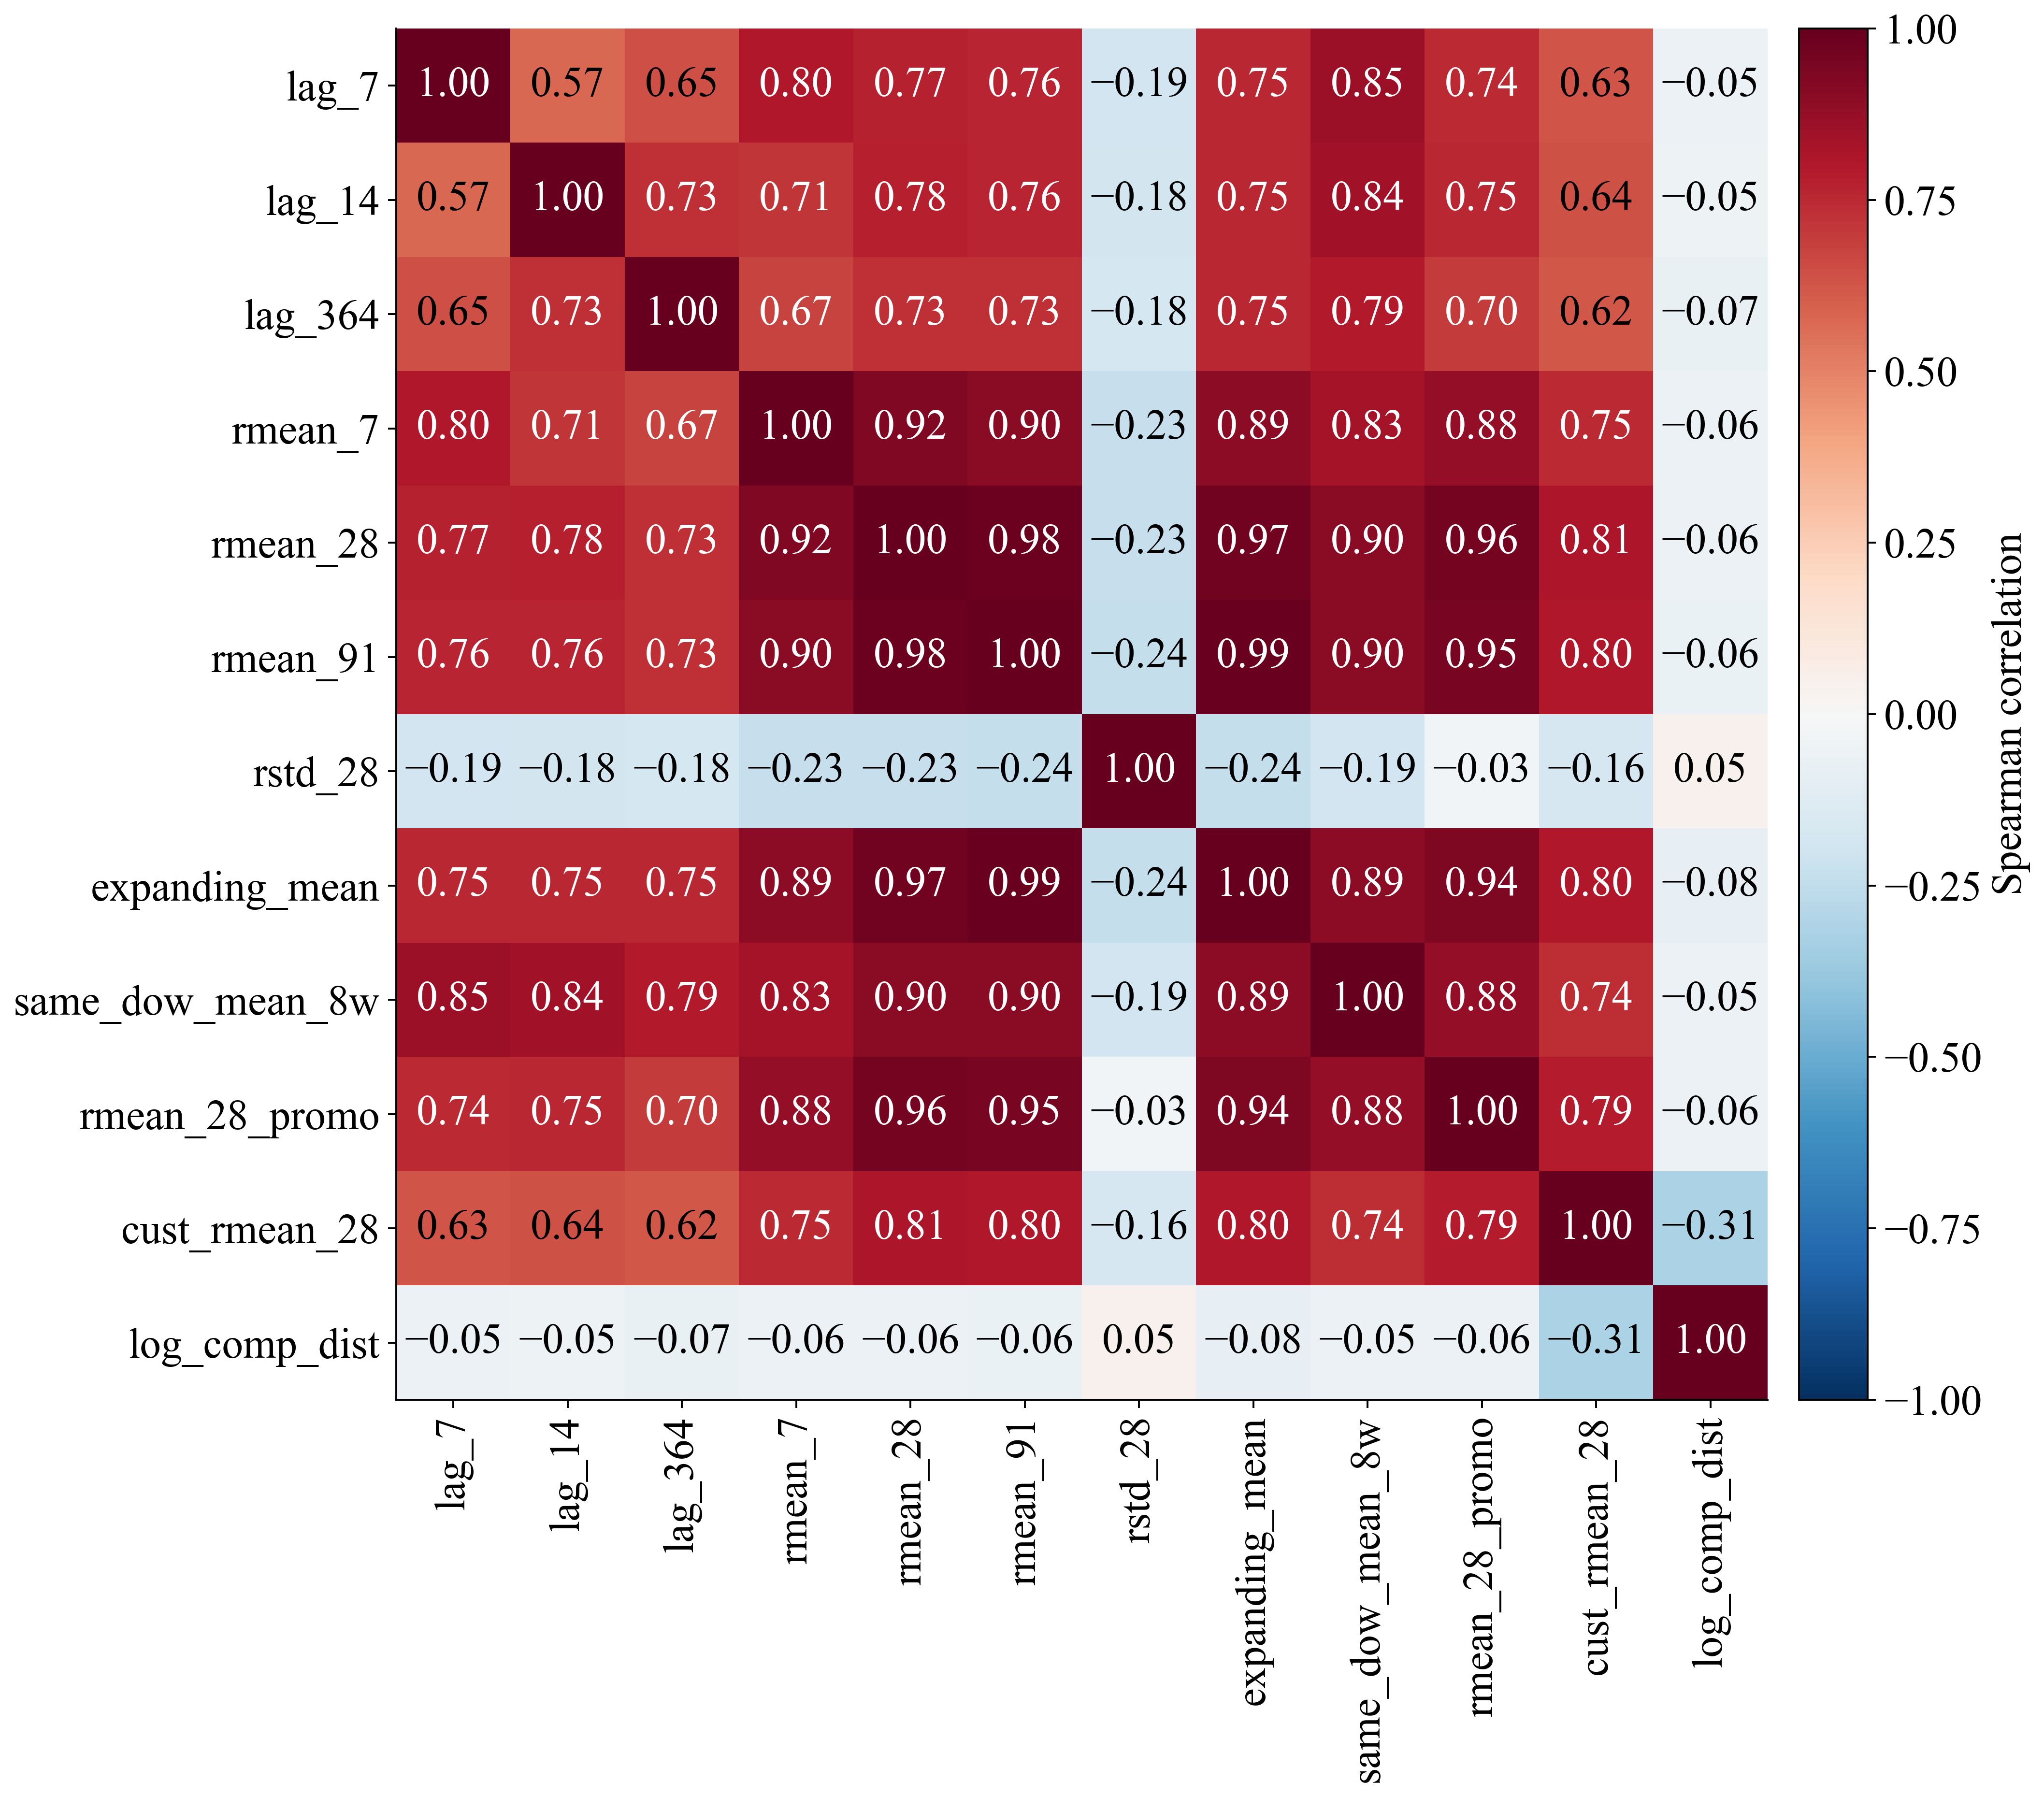

In [10]:
def contrast_text(value, image):
    rgb = np.asarray(image.cmap(image.norm(value))[:3])
    linear = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    luminance = float(linear @ np.array([0.2126, 0.7152, 0.0722]))
    return "black" if luminance > 0.179 else "white"


hist_cols = [
    "lag_7",
    "lag_14",
    "lag_364",
    "rmean_7",
    "rmean_28",
    "rmean_91",
    "rstd_28",
    "expanding_mean",
    "same_dow_mean_8w",
    "rmean_28_promo",
    "cust_rmean_28",
    "log_comp_dist",
]
corr = sample[hist_cols].corr("spearman")
fig, ax = plt.subplots(figsize=(12.5, 11))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(hist_cols)))
ax.set_yticks(range(len(hist_cols)))
ax.set_xticklabels(hist_cols, rotation=90)
ax.set_yticklabels(hist_cols)
for i in range(len(hist_cols)):
    for j in range(len(hist_cols)):
        v = corr.values[i, j]
        ax.text(
            j,
            i,
            f"{0.0 if abs(v)<0.005 else v:.2f}".replace("-", "−"),
            ha="center",
            va="center",
            fontsize=18,
            color=contrast_text(v, im),
        )
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
cb.set_label("Spearman correlation")
cb.ax.tick_params(labelsize=18)

fig.tight_layout()
save_fig(fig, "fig2_2_feature_correlation")
print(f"condition number of the standardised numeric design matrix: {cond:,.0f}")
show_fig("fig2_2_feature_correlation", width=1300)
corr.to_csv(TABLES / "fig2_2_spearman_matrix_numeric.csv")


## 5. Structure, non-linearities and interactions

In [11]:
# (a) ACF of store-demeaned log sales on training rows, pooled over stores
wide_tr = wide_y.loc[
    : design["fit_label_cutoff"],
    np.setdiff1d(wide_y.columns, design["external_stores"]),
]
dm = (wide_tr - wide_tr.mean()).to_numpy()


def pooled_acf(lag):
    a, b = dm[lag:], dm[:-lag]
    m = ~np.isnan(a) & ~np.isnan(b)
    return float(np.corrcoef(a[m], b[m])[0, 1])


acf_lags = list(range(1, 36)) + [42, 49, 56, 91, 182, 364]
acf = pd.Series([pooled_acf(l) for l in acf_lags], index=acf_lags)

# (b) store profiles: level, dispersion, weekday shape, promo uplift, customer intensity -> PCA
from sklearn.decomposition import PCA

sp_rows = trn.assign(
    dev_log=trn["log_sales"] - trn.groupby("Store")["log_sales"].transform("mean")
)
prof_dow = sp_rows.groupby(["Store", "dow"])["dev_log"].mean().unstack("dow").fillna(0)
prof_dow.columns = [f"dow_{c}" for c in prof_dow.columns]
prof_promo = sp_rows.groupby(["Store", "promo"])["log_sales"].mean().unstack("promo")
prof = (
    pd.DataFrame(
        {
            "level": trn.groupby("Store")["log_sales"].mean(),
            "dispersion": trn.groupby("Store")["log_sales"].std(),
            "promo_uplift": prof_promo[1] - prof_promo[0],
            "log_customers": np.log(trn.groupby("Store")["Customers"].mean()),
            "sales_per_customer": trn.groupby("Store")["Sales"].sum()
            / trn.groupby("Store")["Customers"].sum(),
        }
    )
    .join(prof_dow)
    .dropna()
)
Zp = (prof - prof.mean()) / prof.std()
pca = PCA(n_components=4, random_state=SEED).fit(Zp)
scores = pca.transform(Zp)
store_attr = (
    trn.drop_duplicates("Store")
    .set_index("Store")
    .loc[prof.index, ["StoreType", "Assortment"]]
)
load = pd.DataFrame(
    pca.components_.T, index=prof.columns, columns=[f"PC{i + 1}" for i in range(4)]
)
load.loc["— explained variance share —"] = pca.explained_variance_ratio_
save_table(
    load,
    "tab2_6_store_profile_pca",
    "Principal components of standardised store profiles (level, dispersion, weekday shape, promotion uplift, customer intensity) on training rows: loadings and explained variance.",
    float_format="%.3f",
)


,PC1,PC2,PC3,PC4
level,0.1468,0.4390,-0.4890,0.4110
dispersion,-0.3511,-0.1140,-0.1044,0.0407
promo_uplift,-0.3678,-0.0682,-0.0463,0.1942
log_customers,0.0687,0.6261,-0.2211,0.1182
sales_per_customer,0.0878,-0.4593,-0.3642,0.4396
dow_1,-0.3734,0.0552,0.0201,0.0953
dow_2,-0.3747,0.1860,0.0483,-0.0696
dow_3,-0.3455,0.1427,0.0043,-0.1446
dow_4,-0.3414,0.0755,-0.0618,0.0344
dow_5,-0.1718,-0.3387,-0.3610,0.1772


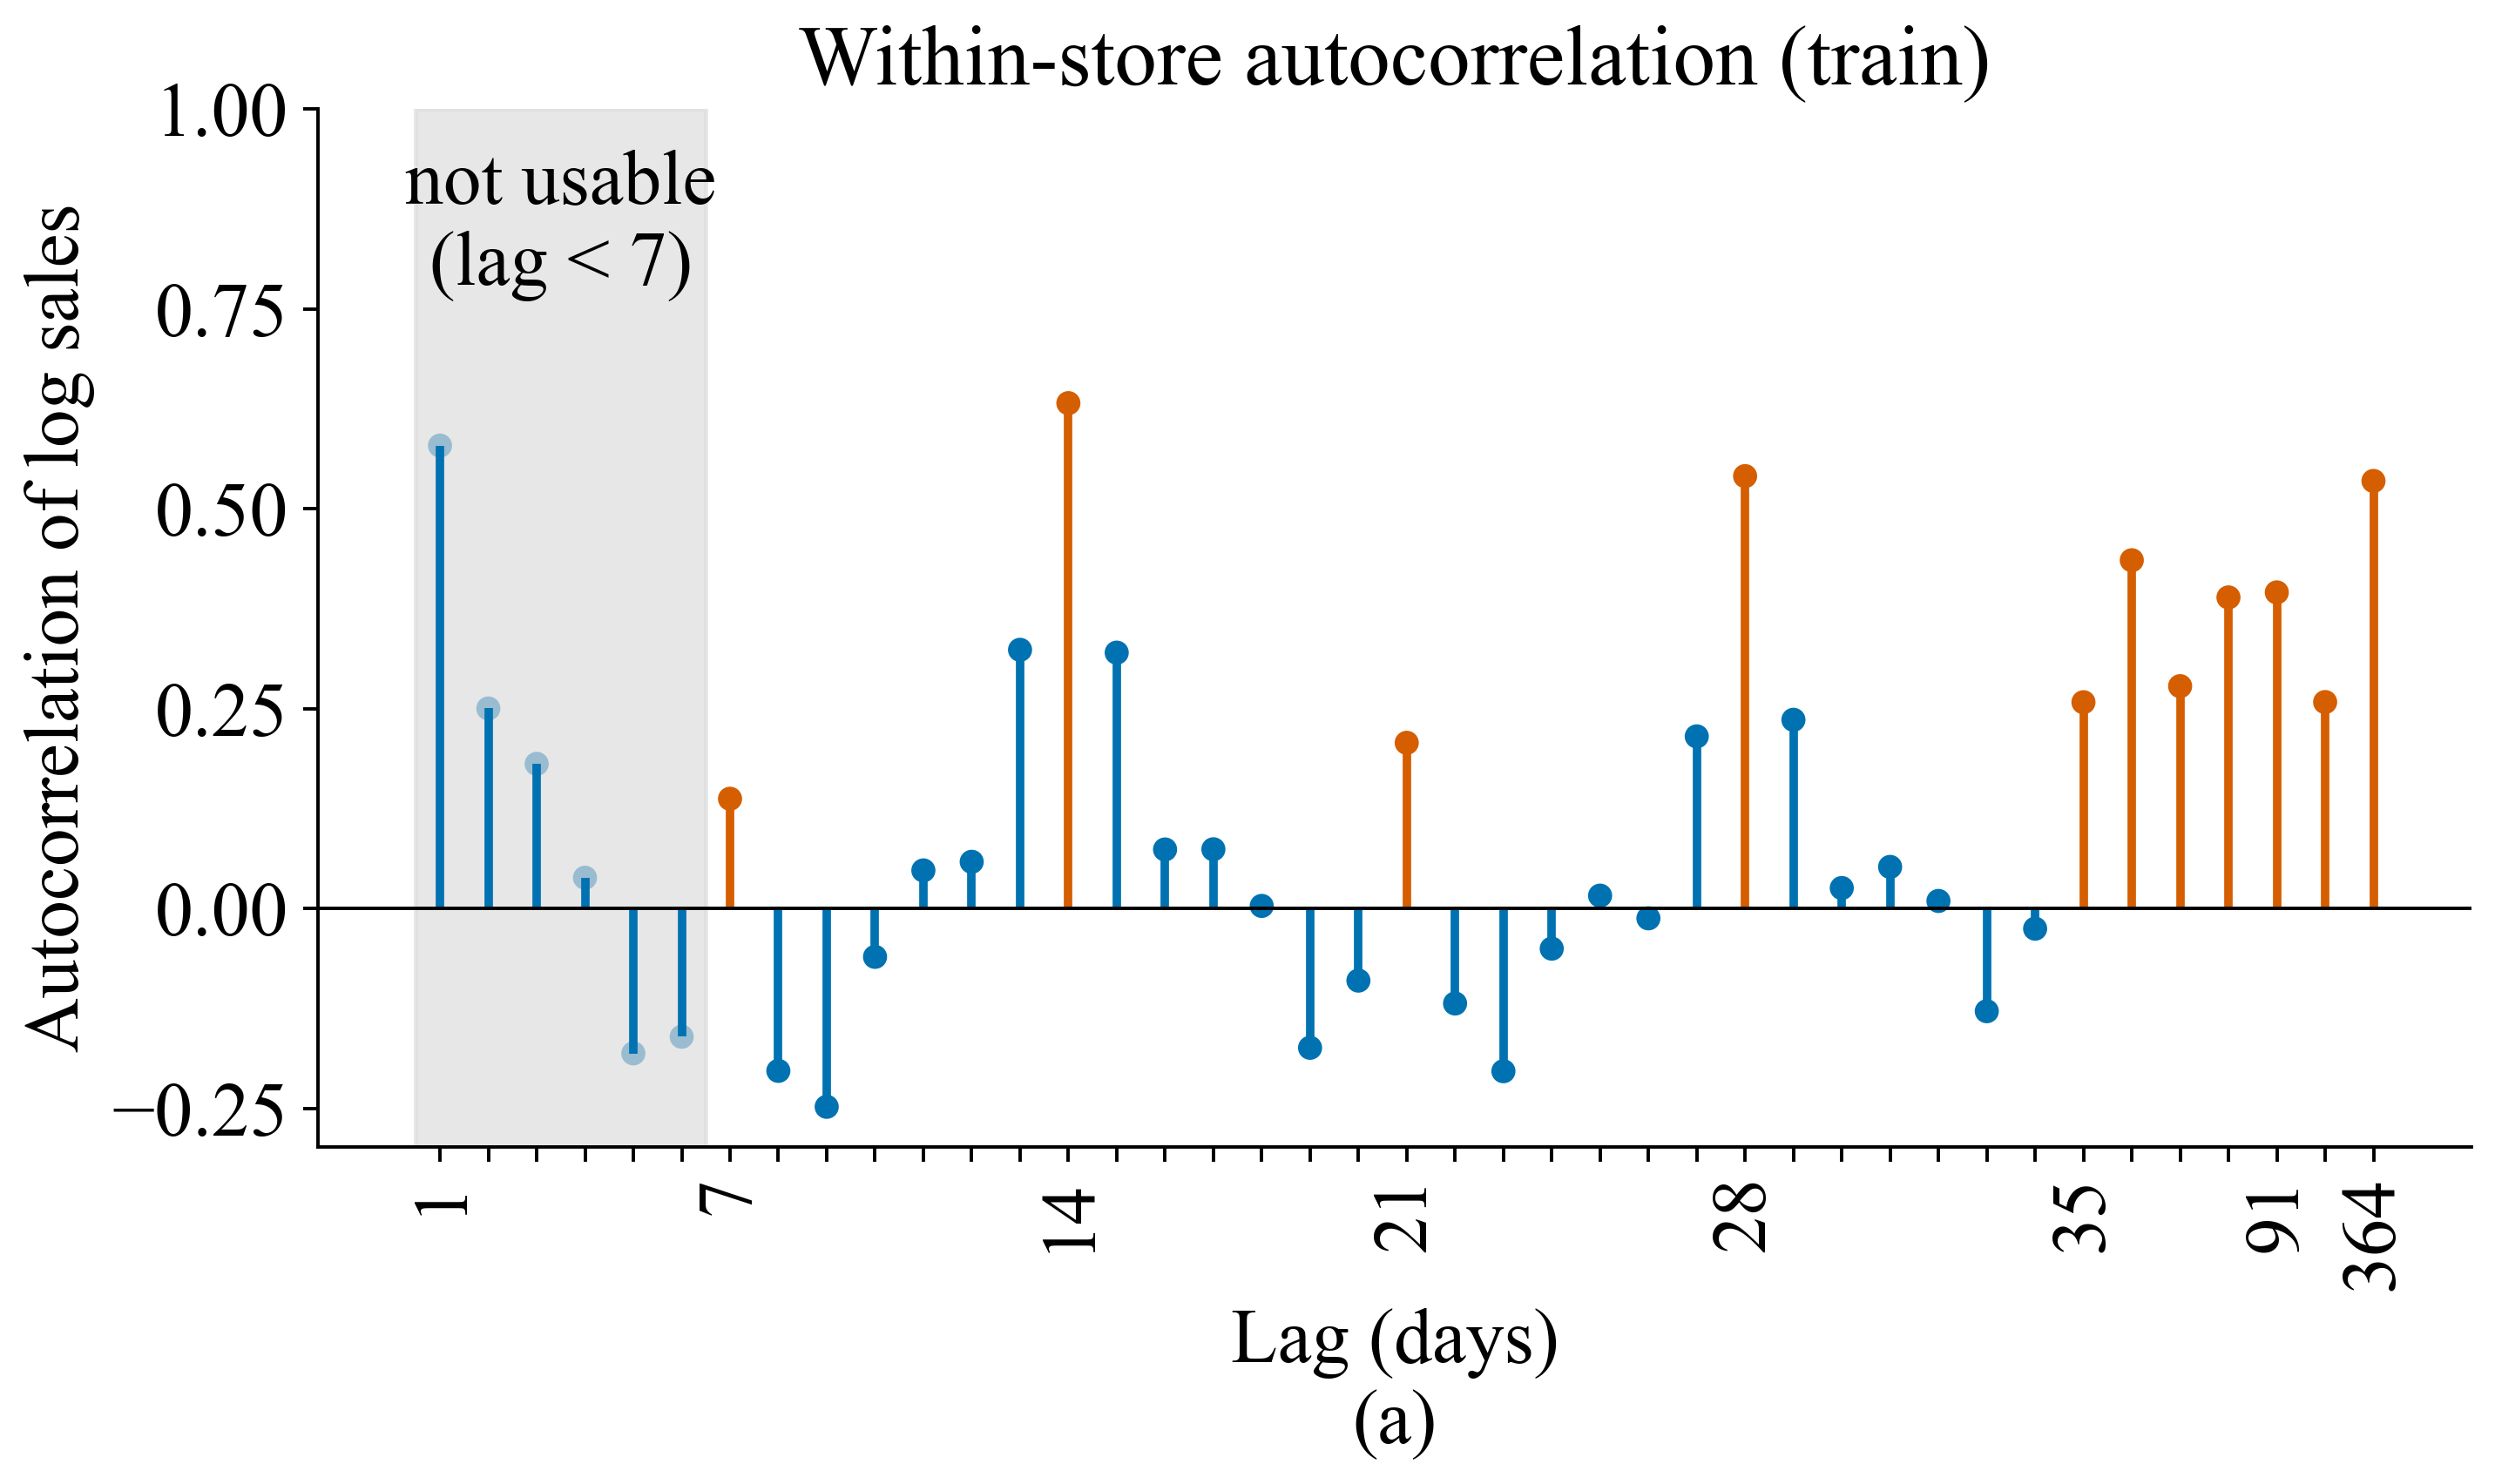

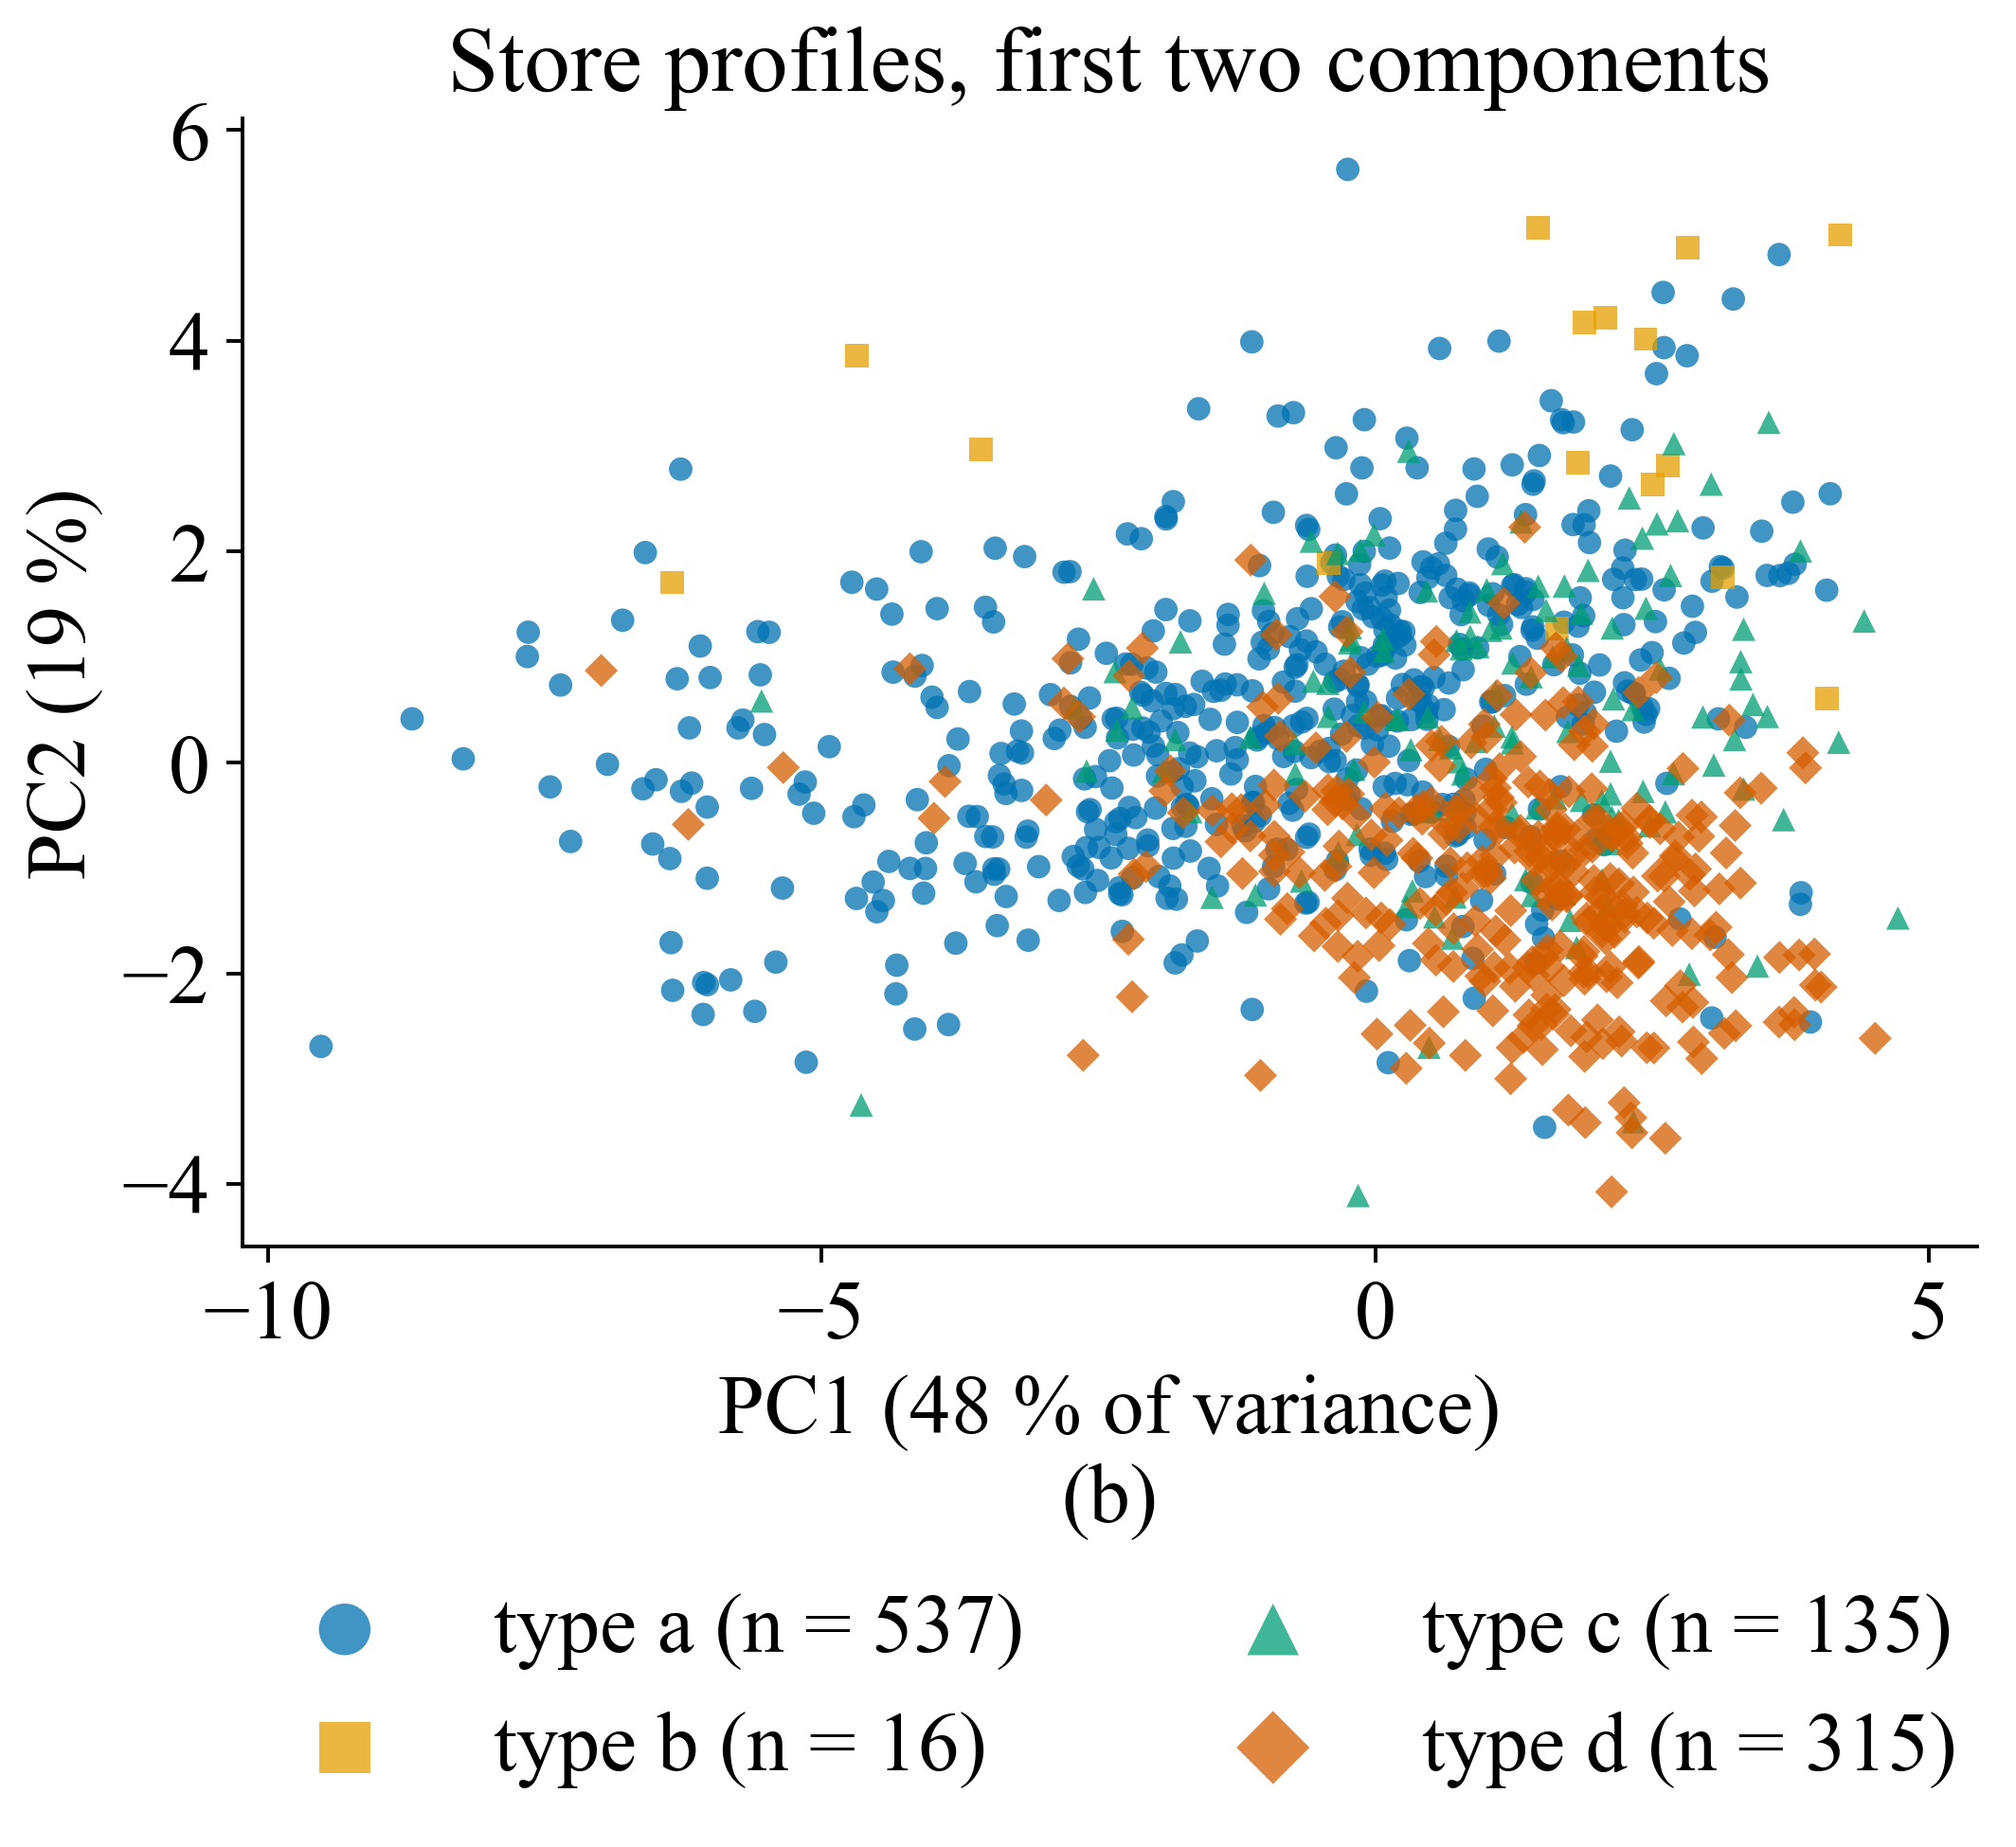

In [12]:
fig, axes = plt.subplots(
    1, 2, figsize=(15, 6.3), gridspec_kw={"width_ratios": [1.35, 1.0]}
)
ax = axes[0]
ax.vlines(
    range(len(acf_lags)),
    0,
    acf.values,
    colors=[PALETTE[3] if l % 7 == 0 else PALETTE[0] for l in acf_lags],
    lw=2,
)
ax.scatter(
    range(len(acf_lags)),
    acf.values,
    color=[PALETTE[3] if l % 7 == 0 else PALETTE[0] for l in acf_lags],
    s=22,
)
ax.axvspan(-0.5, acf_lags.index(6) + 0.5, color="#DDDDDD", alpha=0.7)
ax.text(2.5, 0.95, "not usable\n(lag < 7)", ha="center", va="top", fontsize=18)
ax.set_xticks(range(len(acf_lags)))
ax.set_xticklabels(
    [str(l) if l in (1, 7, 14, 21, 28, 35, 91, 364) else "" for l in acf_lags],
    rotation=90,
)
ax.set_xlabel("Lag (days)")
ax.set_ylabel("Autocorrelation of log sales")
ax.set_ylim(min(-0.05, float(acf.min()) - 0.05), 1)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Within-store autocorrelation (train)")
ax = axes[1]
for i, t in enumerate(["a", "b", "c", "d"]):
    m = (store_attr["StoreType"] == t).to_numpy()
    ax.scatter(
        scores[m, 0],
        scores[m, 1],
        s=26,
        marker=["o", "s", "^", "D"][i],
        color=PALETTE[i],
        alpha=0.75,
        label=f"type {t} (n = {m.sum()})",
        edgecolor="none",
    )
ax.set_xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.0f} % of variance)")
ax.set_ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.0f} %)")
ax.set_title("Store profiles, first two components")
ax.legend(
    frameon=False,
    markerscale=2.2,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.24),
    ncol=2,
)
label_panels(axes)
fig.tight_layout()
save_fig(fig, "fig2_3_temporal_and_store_structure")
show_fig("fig2_3_temporal_and_store_structure")
pd.DataFrame({"lag_days": acf_lags, "autocorrelation": acf.values}).to_csv(
    TABLES / "fig2_3_autocorrelation_numeric.csv", index=False
)
pd.DataFrame(
    {
        "Store": store_attr.index,
        "StoreType": store_attr.StoreType.values,
        "PC1": scores[:, 0],
        "PC2": scores[:, 1],
    }
).to_csv(TABLES / "fig2_3_store_pca_numeric.csv", index=False)


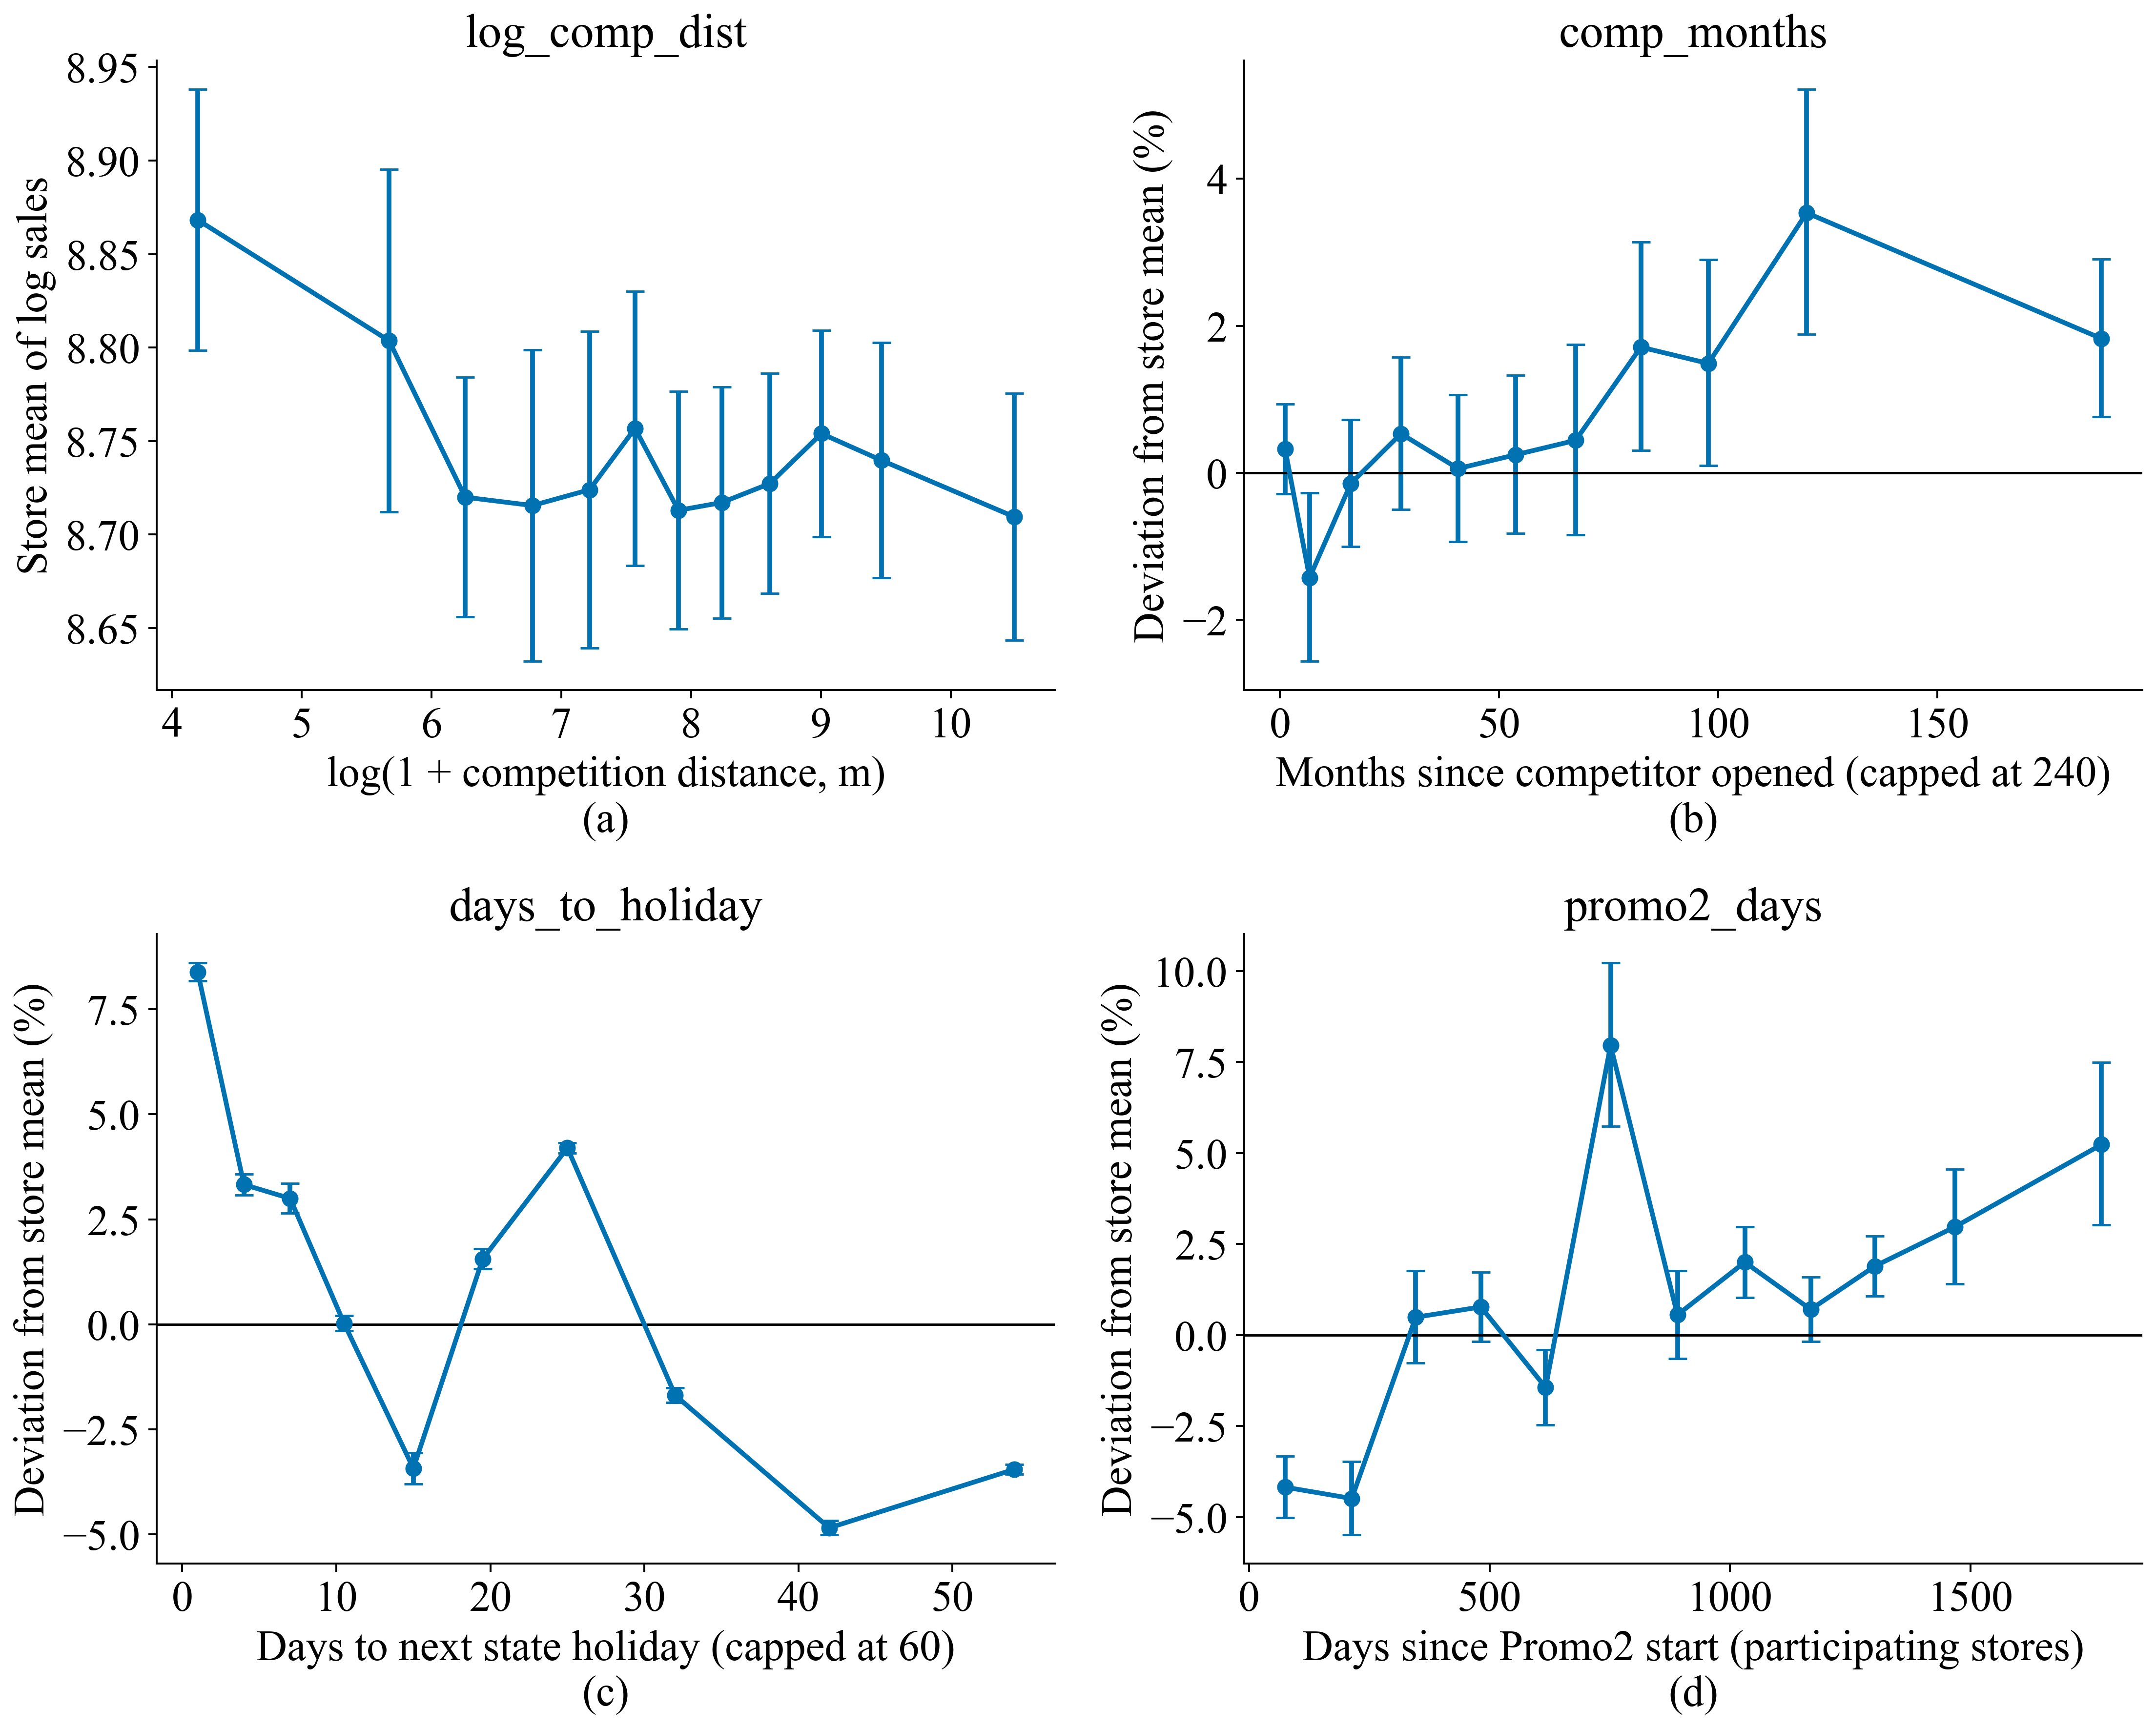

In [13]:
def binned_curve(frame, x, nbins=12, by_store=False):
    """Mean store-demeaned log sales (or store means, by_store=True) per quantile bin of x with 95 % t interval across stores; equal store weighting within each bin."""
    if by_store:
        g = frame.groupby("Store").agg(x=(x, "first"), y=("log_sales", "mean")).dropna()
    else:
        g = pd.DataFrame(
            {
                "x": frame[x],
                "y": frame["log_sales"]
                - frame.groupby("Store")["log_sales"].transform("mean"),
                "Store": frame["Store"],
            }
        ).dropna()
    edges = np.unique(np.quantile(g["x"], np.linspace(0, 1, nbins + 1)))
    g["bin"] = pd.cut(g["x"], edges, include_lowest=True)
    if by_store:
        agg = g.groupby("bin", observed=True)["y"].agg(["mean", "std", "size"])
    else:
        # One mean per store and bin; avoid treating dependent store-days as independent.
        store_bin = g.groupby(["Store", "bin"], observed=True)["y"].mean().reset_index()
        agg = store_bin.groupby("bin", observed=True)["y"].agg(["mean", "std", "size"])
    agg["centre"] = [iv.mid for iv in agg.index]
    agg["ci"] = stats.t.ppf(0.975, agg["size"] - 1) * agg["std"] / np.sqrt(agg["size"])
    return agg


curves = {
    "log_comp_dist": (
        "log(1 + competition distance, m)",
        "Store mean of log sales",
        True,
    ),
    "comp_months": (
        "Months since competitor opened (capped at 240)",
        "Deviation from store mean (log)",
        False,
    ),
    "days_to_holiday": (
        "Days to next state holiday (capped at 60)",
        "Deviation from store mean (log)",
        False,
    ),
    "promo2_days": (
        "Days since Promo2 start (participating stores)",
        "Deviation from store mean (log)",
        False,
    ),
}
fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))
for ax, (x, (xl, yl, by_store)) in zip(axes.ravel(), curves.items()):
    fr = (
        trn[trn["promo2_days"] > 0]
        if x == "promo2_days"
        else (
            trn.assign(comp_months=trn["comp_months"].clip(upper=240))
            if x == "comp_months"
            else trn
        )
    )
    c = binned_curve(fr, x, by_store=by_store)
    c.to_csv(TABLES / ("fig2_4_" + x + "_numeric.csv"))
    ax.errorbar(
        c["centre"],
        (
            100 * (np.exp(c["mean"] - (0 if by_store else 0)) - 1)
            if not by_store
            else c["mean"]
        ),
        yerr=(
            np.vstack(
                [
                    100 * (np.exp(c["mean"]) - np.exp(c["mean"] - c["ci"])),
                    100 * (np.exp(c["mean"] + c["ci"]) - np.exp(c["mean"])),
                ]
            )
            if not by_store
            else c["ci"]
        ),
        fmt="o-",
        color=PALETTE[0],
        lw=2,
        capsize=4,
    )
    ax.set_xlabel(xl)
    ax.set_ylabel(yl if by_store else "Deviation from store mean (%)")
    if not by_store:
        ax.axhline(0, color="black", lw=1)
    ax.set_title(x)
label_panels(axes)
fig.tight_layout()
save_fig(fig, "fig2_4_nonlinear_responses")
show_fig("fig2_4_nonlinear_responses", width=1500)


In [14]:
inter = (
    trn.groupby(["Store", "StoreType", "Assortment", "promo"])["log_sales"]
    .mean()
    .unstack("promo")
)
inter["uplift %"] = 100 * (np.exp(inter[1] - inter[0]) - 1)
by_type = inter.groupby("StoreType")["uplift %"].agg(["median", "mean", "std", "size"])
by_type.index = [f"StoreType {t}" for t in by_type.index]
by_assort = inter.groupby("Assortment")["uplift %"].agg(
    ["median", "mean", "std", "size"]
)
by_assort.index = [f"Assortment {a}" for a in by_assort.index]
wd = trn.groupby(["Store", "dow", "promo"])["log_sales"].mean().unstack("promo")
wd["uplift %"] = 100 * (np.exp(wd[1] - wd[0]) - 1)
by_dow = wd.groupby("dow")["uplift %"].agg(["median", "mean", "std", "size"])
by_dow.index = [f"Weekday {d}" for d in by_dow.index]
interactions = pd.concat([by_type, by_assort, by_dow.dropna()])
interactions.columns = [
    "median uplift %",
    "mean uplift %",
    "sd across stores",
    "stores",
]
kw_t = stats.kruskal(*[g["uplift %"].dropna() for _, g in inter.groupby("StoreType")])
kw_a = stats.kruskal(*[g["uplift %"].dropna() for _, g in inter.groupby("Assortment")])
save_table(
    interactions,
    "tab2_7_promotion_interactions",
    "Per-store promotion uplift of log sales by store type, assortment and weekday (training rows): interaction of the schedule with store attributes and the calendar.",
    float_format="%.3g",
)


,median uplift %,mean uplift %,sd across stores,stores
StoreType a,44.7623,47.2505,20.4441,537
StoreType b,11.6245,22.3780,25.2345,16
StoreType c,35.6438,36.9844,16.1342,135
StoreType d,36.5649,38.2905,14.6446,315
Assortment a,45.7951,47.4781,20.9775,533
Assortment b,10.0635,7.7419,6.0115,8
Assortment c,36.9598,37.7017,14.4468,462
Weekday 1,58.8063,61.6631,23.7377,1003
Weekday 2,47.3953,48.6921,15.6385,1003
Weekday 3,36.9431,37.5599,11.4794,1003


In [15]:
inter_tests = pd.DataFrame(
    [
        {
            "factor": "store type",
            "levels": 4,
            "stores": int(inter["uplift %"].notna().sum()),
            "test": "Kruskal–Wallis on per-store uplift",
            "statistic": kw_t.statistic,
            "p-value": kw_t.pvalue,
            "epsilon squared": (kw_t.statistic - 3)
            / (inter["uplift %"].notna().sum() - 4),
        },
        {
            "factor": "assortment",
            "levels": 3,
            "stores": int(inter["uplift %"].notna().sum()),
            "test": "Kruskal–Wallis on per-store uplift",
            "statistic": kw_a.statistic,
            "p-value": kw_a.pvalue,
            "epsilon squared": (kw_a.statistic - 2)
            / (inter["uplift %"].notna().sum() - 3),
        },
    ]
).set_index("factor")
save_table(
    inter_tests,
    "tab2_7b_promotion_interaction_tests",
    "Does the promotion uplift differ between store types and assortments? Kruskal–Wallis tests on the per-store uplift with epsilon-squared effect sizes.",
    float_format="%.4g",
)


,levels,stores,test,statistic,p-value,epsilon squared
factor,,,,,,
store type,4,1003,Kruskal–Wallis on per-store uplift,72.6985,1.13e-15,0.0698
assortment,3,1003,Kruskal–Wallis on per-store uplift,80.0727,4.1e-18,0.0781


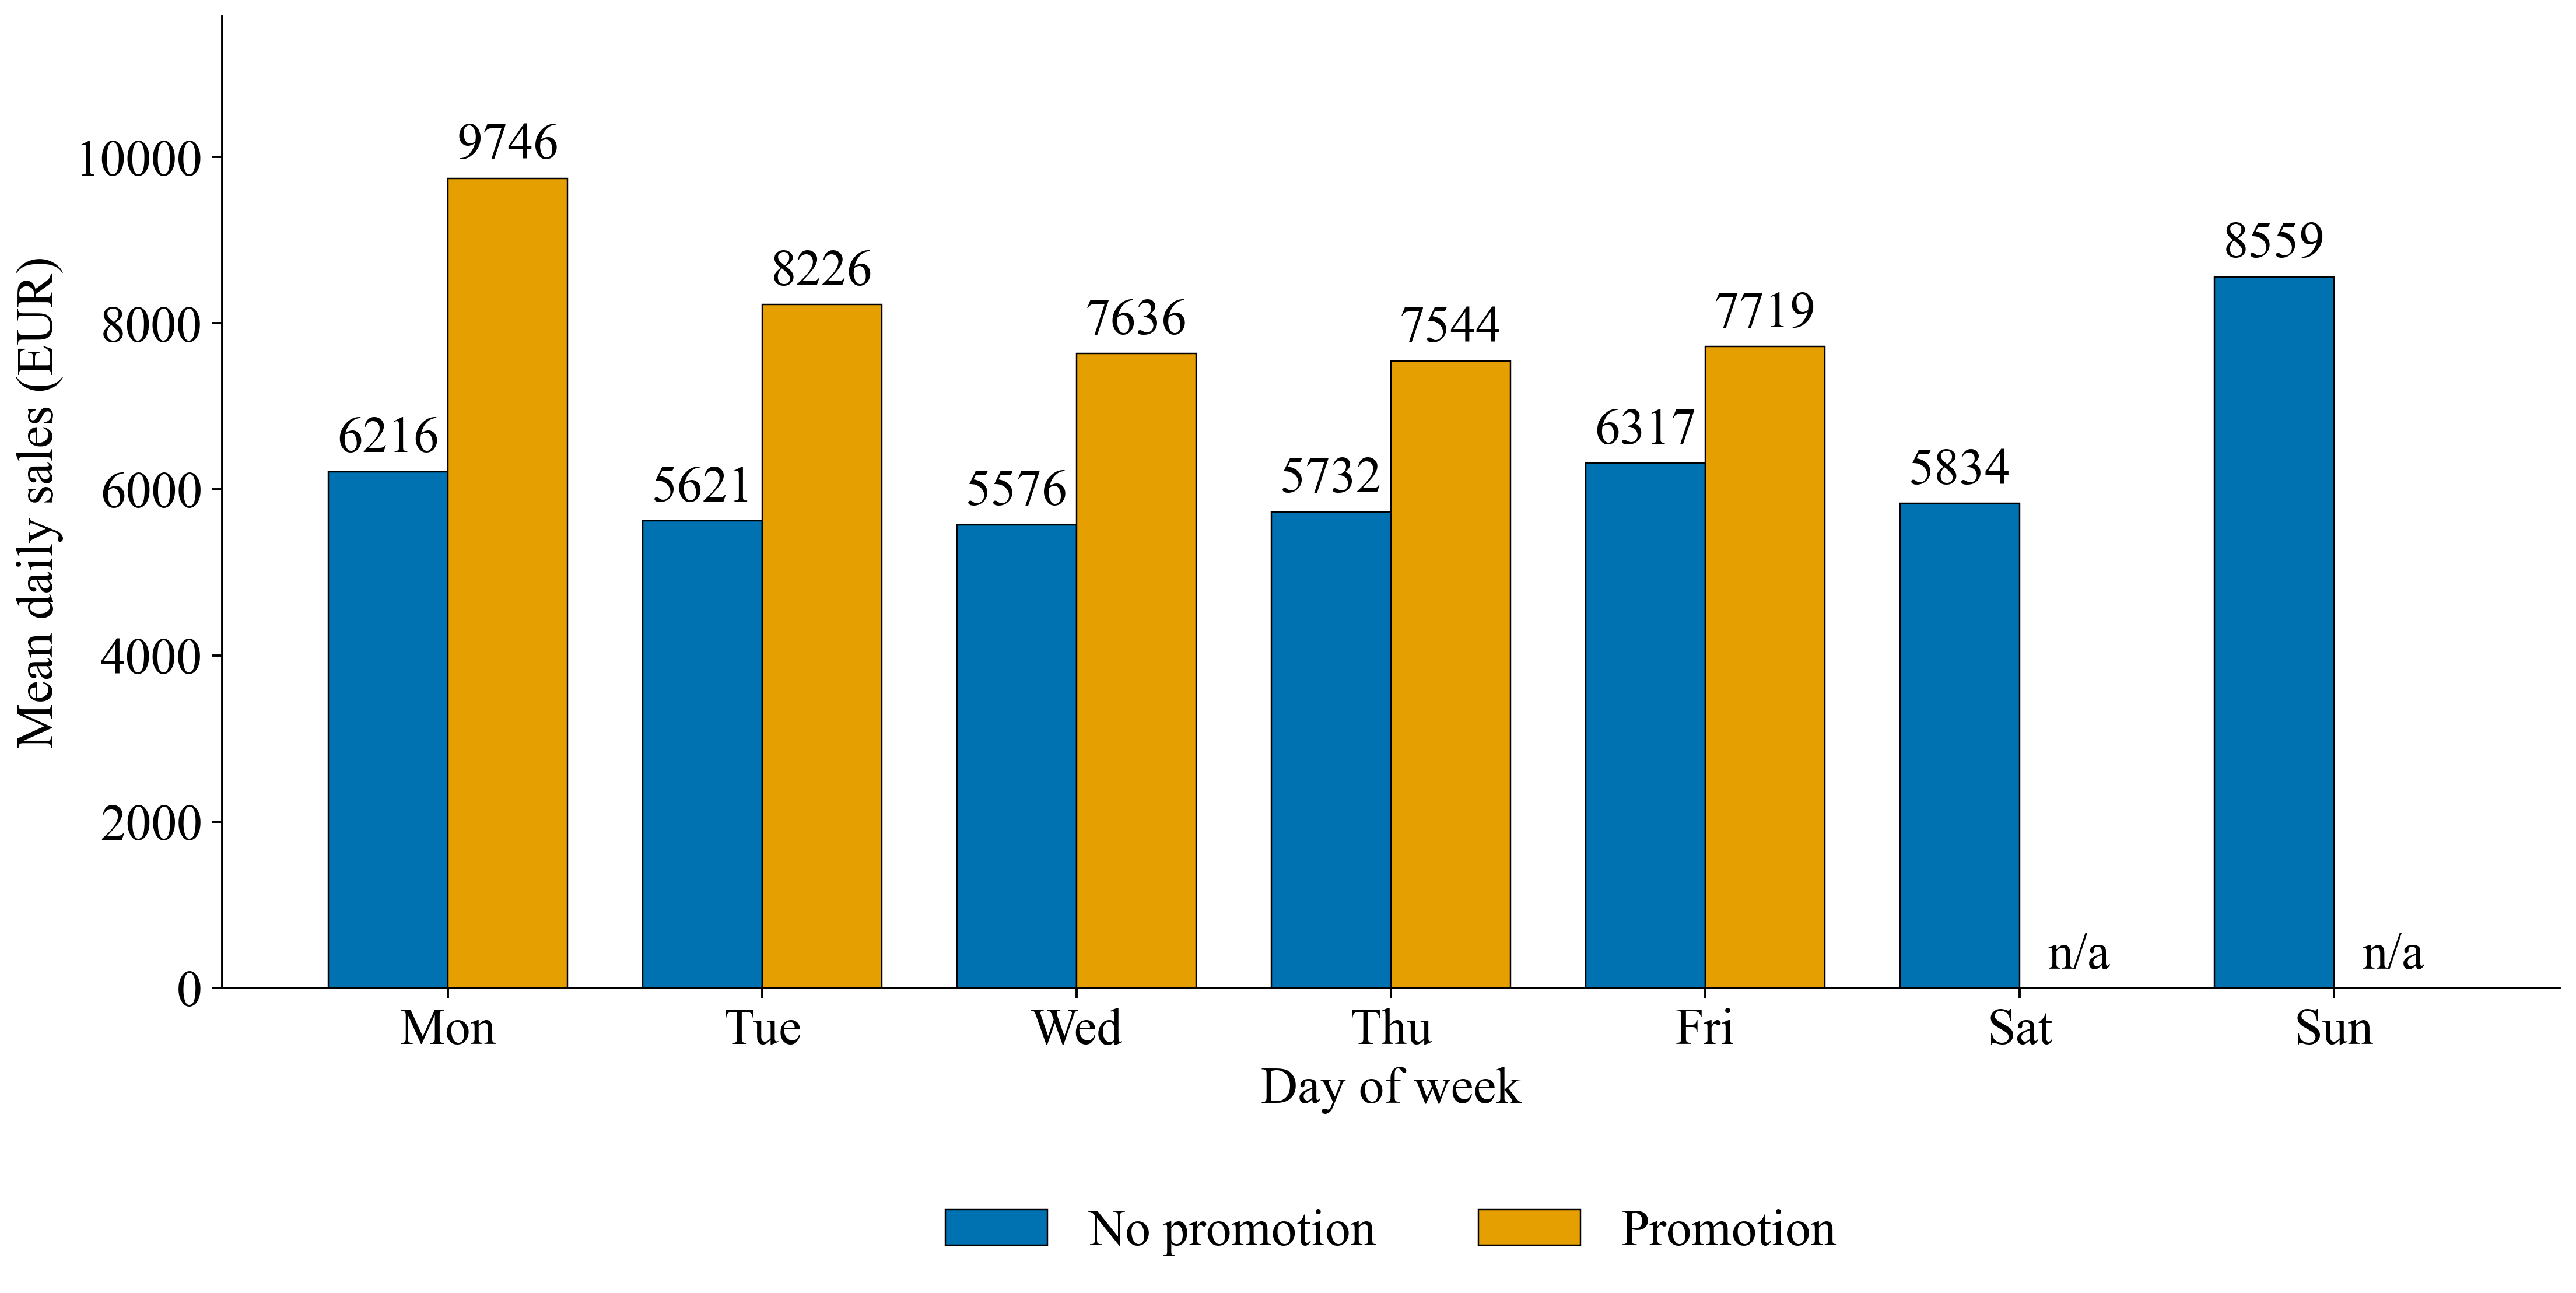

In [16]:
prof_wd = trn.groupby(["dow", "promo"])["Sales"].mean().unstack("promo")
prof_wd.columns = ["no promotion", "promotion"]
fig, ax = plt.subplots(figsize=(13, 6.8))
x = np.arange(1, 8)
w = 0.38
b1 = ax.bar(
    x - w / 2,
    prof_wd["no promotion"],
    w,
    color=PALETTE[0],
    edgecolor="black",
    lw=0.5,
    label="No promotion",
)
b2 = ax.bar(
    x + w / 2,
    prof_wd["promotion"].fillna(0),
    w,
    color=PALETTE[1],
    edgecolor="black",
    lw=0.5,
    label="Promotion",
)
ax.set_xticks(x)
ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_ylabel("Mean daily sales (EUR)")
ax.set_xlabel("Day of week")
ax.bar_label(b1, fmt="%.0f", padding=3, fontsize=18)
ax.bar_label(
    b2,
    labels=[f"{v:.0f}" if pd.notna(v) else "n/a" for v in prof_wd["promotion"]],
    padding=3,
    fontsize=18,
)
ax.set_ylim(0, prof_wd.max().max() * 1.20)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
fig.tight_layout()
save_fig(fig, "fig2_5_weekday_promo_profile")
_ = save_table(
    prof_wd,
    "tab2_8_weekday_promo_profile",
    "Mean daily sales by weekday and promotion status (training partition); plotted once.",
    float_format="%.0f",
)
show_fig("fig2_5_weekday_promo_profile", width=1100)


## 6. Preliminary signal check: how much of the variance is forecastable?

In [17]:
def rmspe(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    m = y != 0
    return float(np.sqrt(np.mean(((y[m] - p[m]) / y[m]) ** 2)))


def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {
        "RMSPE": rmspe(y, p),
        "RMSE": float(np.sqrt(np.mean((y - p) ** 2))),
        "MAE": float(np.mean(np.abs(y - p))),
        "sMAPE": float(np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p)))),
        "R2": float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)),
    }


quick = lgb.LGBMRegressor(
    n_estimators=600,
    learning_rate=0.05,
    num_leaves=63,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=SEED,
    n_jobs=PREPROCESS_N_JOBS,
    verbose=-1,
)
print("Preliminary LightGBM: all feature groups", flush=True)
quick.fit(trn[FEATURES], trn["log_sales"], categorical_feature=CATEGORICAL)
p_val = np.exp(quick.predict(val[FEATURES]))
fallback = (
    val["rmean_28"].fillna(val["expanding_mean"]).fillna(trn["log_sales"].median())
)
rows = {
    "Rossmann: naive (same weekday mean, 8 weeks)": metrics(
        val["Sales"], np.exp(val["same_dow_mean_8w"].fillna(fallback))
    ),
    "Rossmann: naive (lag 7)": metrics(
        val["Sales"], np.exp(val["lag_7"].fillna(fallback))
    ),
    "Rossmann: LightGBM default (all groups)": metrics(val["Sales"], p_val),
}
for g, cols in GROUPS.items():
    print("Preliminary LightGBM: omit " + g, flush=True)
    m = lgb.LGBMRegressor(
        n_estimators=600,
        learning_rate=0.05,
        num_leaves=63,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=SEED,
        n_jobs=PREPROCESS_N_JOBS,
        verbose=-1,
    )
    sub = [c for c in FEATURES if c not in cols]
    m.fit(
        trn[sub],
        trn["log_sales"],
        categorical_feature=[c for c in CATEGORICAL if c in sub],
    )
    rows[f"Rossmann: LightGBM without {g.replace('_', ' ')}"] = metrics(
        val["Sales"], np.exp(m.predict(val[sub]))
    )
prelim = pd.DataFrame(rows).T
save_table(
    prelim,
    "tab2_9_preliminary_signal",
    "Preliminary validation accuracy (Jan–Apr 2015) of naive forecasts and a default LightGBM with feature-group drop-out.",
)


Preliminary LightGBM: all feature groups
Preliminary LightGBM: omit G1_calendar
Preliminary LightGBM: omit G2_schedule
Preliminary LightGBM: omit G3_store
Preliminary LightGBM: omit G4_history
Preliminary LightGBM: omit G5_customers
Preliminary LightGBM: omit G6_movable_calendar
Preliminary LightGBM: omit G7_schedule


,RMSPE,RMSE,MAE,sMAPE,R2
"Rossmann: naive (same weekday mean, 8 weeks)",0.2862,"1,756.4665","1,270.8714",0.1827,0.6521
Rossmann: naive (lag 7),0.3872,"2,532.5728","1,931.0360",0.2761,0.2768
Rossmann: LightGBM default (all groups),0.1401,887.0983,595.9452,0.0877,0.9113
Rossmann: LightGBM without G1 calendar,0.1492,962.0929,645.2225,0.0941,0.8956
Rossmann: LightGBM without G2 schedule,0.1477,936.2867,619.8065,0.0907,0.9012
Rossmann: LightGBM without G3 store,0.1419,891.1739,595.8050,0.0877,0.9104
Rossmann: LightGBM without G4 history,0.1684,"1,018.9128",696.1569,0.1021,0.8829
Rossmann: LightGBM without G5 customers,0.1413,888.9960,597.6915,0.0883,0.9109
Rossmann: LightGBM without G6 movable calendar,0.1570,906.2606,607.2696,0.0896,0.9074
Rossmann: LightGBM without G7 schedule,0.1374,893.5748,608.4281,0.0894,0.9100


## 7. Leakage-safe preprocessing decisions, inner folds and persistence

In [19]:
decisions = pd.DataFrame(
    [
        (
            "missing store attributes (competition, Promo2)",
            "NB01 Tab. 1.5–1.6: development-store missingness and Promo2 non-participation",
            "kept as NaN (native handling)",
            "training median + missing indicator",
        ),
        (
            "missing history (panel start, 2014 gap)",
            "NB01 Tab. 1.6; Tab. 2.2 (lag_364 availability)",
            "kept as NaN",
            "training median + missing indicator for features with > 0.5 % missing",
        ),
        (
            "contradictory rows (open with zero sales, closed with sales)",
            "NB01 Tab. 1.6",
            "removed by the row filter fixed in NB01",
            "same",
        ),
        (
            "outliers of the target",
            "NB01 Tab. 1.7, Fig. 1.2c: rare pronounced tails remain after log",
            "none removed; log target",
            "none removed; log target",
        ),
        (
            "target skewness",
            "NB01 Fig. 1.3",
            "log transform, back-transformed for metrics",
            "same",
        ),
        (
            "categorical codes (weekday, holiday, store type, assortment, month position)",
            "Sections 3 and 5: regime effects and interactions",
            "integer codes declared categorical",
            "one-hot on training levels",
        ),
        (
            "feature scale",
            "Tab. 2.5: heterogeneous ranges",
            "none (invariant)",
            "z-score with training mean and sd",
        ),
        (
            "multicollinearity of the history block",
            "Tab. 2.5: VIF > 10, |r| > 0.8",
            "kept; attribution interpreted cautiously",
            "kept; ridge / weight decay regularisation in NB03–NB04",
        ),
        (
            "covariate shift between periods",
            "Tab. 2.2–2.3",
            "chronological selection on valid; adaptive weighting in NB05",
            "same",
        ),
        (
            "class/target imbalance",
            "regression task",
            "not applicable",
            "not applicable",
        ),
        (
            "feature selection",
            "Tab. 2.9: schedule/history strongest; customer-history difference small",
            "no selection; all 54 features",
            "same",
        ),
    ],
    columns=["issue", "evidence", "tree models", "linear / kNN / neural models"],
).set_index("issue")
save_table(
    decisions,
    "tab2_11_preprocessing_decisions",
    "Preprocessing decisions, the evidence that motivates each one, and the treatment per model family; all parameters are estimated on the training partition only.",
    index=True,
)


,evidence,tree models,linear / kNN / neural models
issue,,,
"missing store attributes (competition, Promo2)",NB01 Tab. 1.5–1.6: development-store missingness and Promo2 non-participation,kept as NaN (native handling),training median + missing indicator
"missing history (panel start, 2014 gap)",NB01 Tab. 1.6; Tab. 2.2 (lag_364 availability),kept as NaN,training median + missing indicator for features with > 0.5 % missing
"contradictory rows (open with zero sales, closed with sales)",NB01 Tab. 1.6,removed by the row filter fixed in NB01,same
outliers of the target,"NB01 Tab. 1.7, Fig. 1.2c: rare pronounced tails remain after log",none removed; log target,none removed; log target
target skewness,NB01 Fig. 1.3,"log transform, back-transformed for metrics",same
"categorical codes (weekday, holiday, store type, assortment, month position)",Sections 3 and 5: regime effects and interactions,integer codes declared categorical,one-hot on training levels
feature scale,Tab. 2.5: heterogeneous ranges,none (invariant),z-score with training mean and sd
multicollinearity of the history block,"Tab. 2.5: VIF > 10, |r| > 0.8",kept; attribution interpreted cautiously,kept; ridge / weight decay regularisation in NB03–NB04
covariate shift between periods,Tab. 2.2–2.3,chronological selection on valid; adaptive weighting in NB05,same


In [20]:
INNER_FOLDS = {
    "F1": {
        "fit_end": "2014-03-25",
        "eval_start": "2014-04-01",
        "eval_end": "2014-06-30",
    },
    "F2": {
        "fit_end": "2014-06-24",
        "eval_start": "2014-07-01",
        "eval_end": "2014-09-30",
    },
    "F3": {
        "fit_end": "2014-09-24",
        "eval_start": "2014-10-01",
        "eval_end": "2014-12-31",
    },
}
fold_tab = []
fold_long = trn[["row_id", "Date"]].copy()
for f, b in INNER_FOLDS.items():
    role = np.select(
        [
            fold_long["Date"] <= b["fit_end"],
            (fold_long["Date"] >= b["eval_start"])
            & (fold_long["Date"] <= b["eval_end"]),
        ],
        ["fit", "eval"],
        "unused",
    )
    fold_long[f] = role
    fold_tab.append(
        {
            "fold": f,
            "fit period": f"2013-01-01 .. {b['fit_end']}",
            "evaluation period": f"{b['eval_start']} .. {b['eval_end']}",
            "fit rows": int((role == "fit").sum()),
            "evaluation rows": int((role == "eval").sum()),
            "stores": int(trn.loc[role == "eval", "Store"].nunique()),
        }
    )
fold_long.drop(columns="Date").to_csv(SPLITS / "rossmann_inner_folds.csv", index=False)
json.dump(
    {
        "scheme": "expanding window inside train; evaluation blocks are disjoint and chronological; fit labels end at least 7 calendar days before each evaluation start",
        "folds": INNER_FOLDS,
    },
    open(CONFIGS / "inner_folds.json", "w"),
    indent=2,
)
fold_tab = pd.DataFrame(fold_tab).set_index("fold")
save_table(
    fold_tab,
    "tab2_12_inner_folds",
    "Inner temporal folds inside the training partition (row identifiers in outputs/data/splits/rossmann_inner_folds.csv).",
    float_format="%.0f",
)


,fit period,evaluation period,fit rows,evaluation rows,stores
fold,,,,,
F1,2013-01-01 .. 2014-03-25,2014-04-01 .. 2014-06-30,374869,72971,1003
F2,2013-01-01 .. 2014-06-24,2014-07-01 .. 2014-09-30,447836,66408,840
F3,2013-01-01 .. 2014-09-24,2014-10-01 .. 2014-12-31,515047,60193,840


In [21]:
prep = {
    "features": FEATURES,
    "categorical": CATEGORICAL,
    "numeric": NUMERIC,
    "groups": GROUPS,
    "median": trn[NUMERIC].median().to_dict(),
    "mean": trn[NUMERIC].mean().to_dict(),
    "std": trn[NUMERIC].std().replace(0, 1).to_dict(),
    "missing_indicator_for": [f for f in NUMERIC if trn[f].isna().mean() > 0.005],
    "categorical_levels": {
        c: sorted(int(v) for v in trn[c].dropna().unique()) for c in CATEGORICAL
    },
    "fitted_on": "train labels available by the first validation forecast (2013-01-01 .. 2014-12-25, 1,003 stores)",
    "label_lag_days": LAG,
    "inner_folds": INNER_FOLDS,
}
json.dump(prep, open(CONFIGS / "preprocessing.json", "w"), indent=2)
keep_cols = [
    "row_id",
    "Store",
    "Date",
    "partition",
    "retained",
    "Sales",
    "log_sales",
] + FEATURES
out = df.loc[df["retained"], keep_cols].reset_index(drop=True)
out.to_parquet(PROCESSED / "rossmann_features.parquet", index=False)
summary = out.groupby("partition").agg(
    rows=("row_id", "size"),
    stores=("Store", "nunique"),
    features=("Store", lambda s: len(FEATURES)),
    missing_hist_pct=("rmean_28", lambda s: 100 * s.isna().mean()),
    missing_lag364_pct=("lag_364", lambda s: 100 * s.isna().mean()),
)
summary = summary.loc[
    ["train", "valid", "test_locked", "external_history", "external_test"]
]
save_table(
    summary,
    "tab2_13_processed_summary",
    "Processed design matrix per partition (retained store-days only); the locked partitions are transformed but not evaluated.",
    float_format="%.2f",
)


,rows,stores,features,missing_hist_pct,missing_lag364_pct
partition,,,,,
train,582862,1003,54,2.0931,53.6395
valid,100336,1003,54,1.9724,3.4365
test_locked,75997,1003,54,0.0000,9.6872
external_history,76650,112,54,2.0209,46.0848
external_test,8493,112,54,0.0000,8.9250


In [22]:
import hashlib

experiment = {
    "experiment_id": RUN_ID.replace("NB02_", "EXP_"),
    "preprocessing_run": RUN_ID,
    "primary_source": design["dataset"],
    "fit_label_cutoff": design["fit_label_cutoff"],
    "selection_label_cutoff": design["selection_label_cutoff"],
    "preprocessing_sha256": hashlib.sha256(
        (CONFIGS / "preprocessing.json").read_bytes()
    ).hexdigest(),
    "processed_sha256": hashlib.sha256(
        (PROCESSED / "rossmann_features.parquet").read_bytes()
    ).hexdigest(),
    "selection_trials_per_family": 8,
    "seeds": list(range(2026, 2031)),
    "status": "development",
}
previous_path = CONFIGS / "current_experiment.json"
previous = json.loads(previous_path.read_text()) if previous_path.exists() else {}
if all(
    previous.get(k) == experiment[k]
    for k in (
        "preprocessing_sha256",
        "processed_sha256",
        "fit_label_cutoff",
        "selection_label_cutoff",
    )
):
    experiment["experiment_id"] = previous["experiment_id"]
    experiment["first_preprocessing_run"] = previous.get(
        "first_preprocessing_run", previous["preprocessing_run"]
    )
(CONFIGS / "current_experiment.json").write_text(json.dumps(experiment, indent=2))
latest_path = MANIFESTS / "latest_runs.json"
latest = json.loads(latest_path.read_text()) if latest_path.exists() else {}
latest["NB02"] = RUN_ID
latest_path.write_text(json.dumps(latest, indent=2));

# Part B · UCI Sales Transactions Weekly

## Causal features and fold-local preprocessing

In [1]:
# NB02_SETUP: paths, feature configuration and helpers
import json, hashlib, time
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'uci'
RUN_ID='NB02_UCI_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')
OUT=BASE/'Artifacts'/RUN_ID; OUT.mkdir(parents=True, exist_ok=True)
for sub in 'Configs Data Manifests'.split():(BASE/sub).mkdir(parents=True,exist_ok=True)
def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
def dump(path, value):
    path.write_text(json.dumps(value, indent=2, allow_nan=False))
# Feature configuration of this panel (fixed before any model fit); later notebooks read it from Configs/feature_contract.json
CONTRACT={'first_origin':6,'last_permitted_origin':38,'lags':[2,3,4,6,8,13],'rolling_windows':[4,8,13],'latest_outcome_offset':-2,
 'rolling_min_periods':1,'rolling_std_ddof':0,'zero_positive_mean_default':0,'identifiers_as_predictors':False,
 'training_origins':[6,26],'initial_oof_selection_latest_label':26,'pending_initial_oof_week':27,'pending_label_release_origin':29,'selection_origins':[28,38],
 'preprocessing':'fixed log1p of count magnitudes, train-fold median imputation, median/IQR scaling; zero IQR uses one; fixed lag missingness indicators',
 'feature_selection':'none','outlier_clipping':False,'outcome_based_exclusions':False}
dump(BASE/'Configs/feature_contract.json',CONTRACT)
DESIGN=json.loads((BASE/'Configs/study_design.json').read_text())
FOLDS=json.loads((BASE/'Configs/inner_folds.json').read_text())
assert CONTRACT['latest_outcome_offset']==DESIGN['latest_available_week_offset']==-2
FONT=font_manager.findfont('Times New Roman', fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_rows',100,'display.max_columns',12,'display.max_colwidth',None,'display.float_format',lambda v:f'{v:.5f}')
def table(frame, name):
    frame.to_csv(OUT/(name+'.csv'), index=False)
    (OUT/(name+'.tex')).write_text(frame.to_latex(index=False,float_format='%.5f',escape=True))
    display(frame)
def figure(fig, name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:
        fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig); display(Image(filename=str(OUT/(name+'.png')),width=900))


### Information set and fixed feature construction

In [2]:
# NB02_FEATURES: visible causal construction, no full-series statistics
panel=pd.read_parquet(BASE/'Data/core_permitted_long.parquet')
assert panel['week'].between(0,38).all() and panel['Product_Code'].nunique()==729
wide=panel.pivot(index='Product_Code',columns='week',values='quantity').sort_index()
assert list(wide.columns)==list(range(39)) and wide.notna().all().all()
CORE_IDS=wide.index.tolist(); LAGS=CONTRACT['lags']; WINDOWS=CONTRACT['rolling_windows']
def build_features(history, origins, market_history):
    """Use only outcome columns through origin minus two; never receive current labels."""
    history=history.sort_index(); market_history=market_history.sort_index()
    frames=[]
    for origin in origins:
        cutoff=origin-2
        assert set(range(cutoff+1)).issubset(history.columns)
        h=history.loc[:,list(range(cutoff+1))].to_numpy(dtype=float)
        mh=market_history.loc[:,list(range(cutoff+1))].to_numpy(dtype=float)
        f=pd.DataFrame(index=history.index)
        for lag in LAGS:
            f[f'lag_{lag}']=history[origin-lag].astype(float) if origin-lag>=0 else np.nan
        for window in WINDOWS:
            recent=h[:,-window:]
            f[f'mean_{window}']=recent.mean(axis=1)
            f[f'std_{window}']=recent.std(axis=1,ddof=0)
            f[f'zero_{window}']=(recent==0).mean(axis=1)
        recent=h[:,-8:]; positive=(recent>0).sum(axis=1)
        f['positive_mean_8']=np.divide(recent.sum(axis=1),positive,out=np.zeros(len(f)),where=positive>0)
        f['max_8']=recent.max(axis=1)
        f['history_mean']=h.mean(axis=1); f['history_std']=h.std(axis=1,ddof=0)
        f['history_zero']=(h==0).mean(axis=1)
        last_positive=np.where(h>0,np.arange(h.shape[1]),-1).max(axis=1)
        f['positive_age']=np.where(last_positive>=0,cutoff-last_positive,h.shape[1]+1)
        f['ever_positive']=(last_positive>=0).astype(float)
        f['history_length']=h.shape[1]; f['week_index']=origin
        f['short_long_change']=(f['mean_4']-f['mean_13'])/(1+f['mean_13'])
        f['recent_level_change']=(f['lag_2']-f['mean_8'])/(1+f['mean_8'])
        f['market_mean_4']=mh[:,-4:].mean(); f['market_mean_13']=mh[:,-13:].mean()
        f['market_zero_4']=(mh[:,-4:]==0).mean()
        f['market_change']=(f['market_mean_4']-f['market_mean_13'])/(1+f['market_mean_13'])
        f.insert(0,'week',origin); f.insert(0,'Product_Code',history.index)
        frames.append(f.reset_index(drop=True))
    return pd.concat(frames,ignore_index=True)
FEATURE_START=time.perf_counter()
X=build_features(wide,range(CONTRACT['first_origin'],39),wide)
FEATURE_SECONDS=time.perf_counter()-FEATURE_START
FEATURES=[c for c in X if c not in ['Product_Code','week']]
assert 'quantity' not in FEATURES and 'Product_Code' not in FEATURES
rows=X.merge(panel[['Product_Code','week','quantity']],on=['Product_Code','week'],validate='one_to_one')
rows.insert(0,'row_id',rows['Product_Code']+'::W'+rows['week'].astype(str))
assert rows['row_id'].is_unique and len(rows)==729*33
missing=X[FEATURES].isna().sum(); nonfinite=np.isinf(X[FEATURES].to_numpy()).sum()
assert nonfinite==0 and set(missing[missing>0].index).issubset({f'lag_{k}' for k in LAGS})
raw_path=BASE/'Data/causal_features_core.parquet'; rows.to_parquet(raw_path,index=False)
feature_summary=pd.DataFrame([{'Feature group':g,'Predictors':n,'Latest outcome':end} for g,n,end in [
 ('Product lag quantities',len(LAGS),'t − 2 or earlier'),('Rolling moments and zero fractions',3*len(WINDOWS),'t − 2'),
 ('Positive-demand, extreme and expanding history',8,'t − 2'),('Known week index',1,'Known at forecast'),
 ('Relative level changes',2,'t − 2'),('Core market context',4,'t − 2')]])
assert feature_summary['Predictors'].sum()==len(FEATURES)
table(feature_summary,'feature_groups')
table(pd.DataFrame({'Feature':missing.index[missing>0],'Missing rows':missing[missing>0].values,'Cause':'Insufficient early history'}),'structural_missingness')
display(Markdown(f'{len(rows):,} product–week rows and {len(FEATURES)} fixed predictors; all 729 core products are retained.'))


,Feature group,Predictors,Latest outcome
0,Product lag quantities,6,t − 2 or earlier
1,Rolling moments and zero fractions,9,t − 2
2,"Positive-demand, extreme and expanding history",8,t − 2
3,Known week index,1,Known at forecast
4,Relative level changes,2,t − 2
5,Core market context,4,t − 2


,Feature,Missing rows,Cause
0,lag_8,1458,Insufficient early history
1,lag_13,5103,Insufficient early history


24,057 product–week rows and 30 fixed predictors; all 729 core products are retained.

### Causality and alignment checks

In [3]:
# NB02_CAUSALITY: prefix, delayed-label, product-isolation and alignment assertions
checks=[]
for origin in range(6,39):
    full=build_features(wide,[origin],wide)
    prefix=wide.loc[:,list(range(origin-1))]
    short=build_features(prefix,[origin],prefix)
    pd.testing.assert_frame_equal(full,short,check_exact=True)
checks.append({'Check':'Physical history truncation','Cases':33,'Result':'Identical features'})
for origin in [6,20,24,28,38]:
    modified=wide.copy(); future=[w for w in modified.columns if w>=origin-1]
    modified.loc[:,future]=999+modified.loc[:,future]*7
    pd.testing.assert_frame_equal(build_features(wide,[origin],wide),build_features(modified,[origin],modified),check_exact=True)
checks.append({'Check':'Replace unavailable outcomes','Cases':5,'Result':'Identical features'})
permuted=wide.iloc[::-1]
pd.testing.assert_frame_equal(build_features(wide,[28],wide),build_features(permuted,[28],permuted),check_exact=True)
checks.append({'Check':'Product-order permutation','Cases':1,'Result':'Identical aligned features'})
changed=wide.copy(); changed.loc[CORE_IDS[1],26]+=100
original=build_features(wide,[28],wide); altered=build_features(changed,[28],changed)
own=[c for c in FEATURES if not c.startswith('market_')]
np.testing.assert_array_equal(original.loc[0,own].to_numpy(),altered.loc[0,own].to_numpy())
assert original.loc[0,'market_mean_4']!=altered.loc[0,'market_mean_4']
assert original.loc[1,'lag_2']!=altered.loc[1,'lag_2']
checks.append({'Check':'Other-product isolation','Cases':1,'Result':'Only shared market context changes'})
checks.append({'Check':'Available-history sensitivity','Cases':1,'Result':'Own lag responds to past change'})
causality=pd.DataFrame(checks); table(causality,'causality_checks')


,Check,Cases,Result
0,Physical history truncation,33,Identical features
1,Replace unavailable outcomes,5,Identical features
2,Product-order permutation,1,Identical aligned features
3,Other-product isolation,1,Only shared market context changes
4,Available-history sensitivity,1,Own lag responds to past change


### Exact folds, row identities and the pending W27 label

In [4]:
# NB02_SPLITS: exact fit/evaluation row identities and release timing
split_records=[]; split_summary=[]
SPLIT_MASKS={}
for fold,spec in FOLDS.items():
    fit=rows['week'].between(6,spec['fit_latest_week'])
    ev=rows['week'].between(*spec['evaluation_weeks'])
    assert not (fit & ev).any() and rows.loc[fit,'week'].max()<=rows.loc[ev,'week'].min()-2
    SPLIT_MASKS[fold]=(fit,ev)
    split_summary.append({'Stage':fold,'Fit weeks':f"W6–W{spec['fit_latest_week']}",'Fit rows':int(fit.sum()),'Forecast weeks':f"W{spec['evaluation_weeks'][0]}–W{spec['evaluation_weeks'][1]}",'Forecast rows':int(ev.sum()),'Labels usable at W28':int((ev & (rows['week']<=26)).sum())})
    for role,mask in [('fit',fit),('forecast',ev)]:
        block=rows.loc[mask,['row_id','Product_Code','week']].copy();block['stage']=fold;block['role']=role
        block['label_release_origin']=block['week']+2;split_records.append(block)
fit=rows['week'].between(6,26); ev=rows['week'].between(28,38)
SPLIT_MASKS['Initial_W28']=(fit,ev)
split_summary.append({'Stage':'Initial W28','Fit weeks':'W6–W26','Fit rows':int(fit.sum()),'Forecast weeks':'W28–W38','Forecast rows':int(ev.sum()),'Labels usable at W28':0})
for role,mask in [('fit',fit),('forecast',ev)]:
    block=rows.loc[mask,['row_id','Product_Code','week']].copy();block['stage']='Initial_W28';block['role']=role;block['label_release_origin']=block['week']+2;split_records.append(block)
split_ids=pd.concat(split_records,ignore_index=True)
split_ids.to_parquet(BASE/'Data/feature_split_ids.parquet',index=False)
table(pd.DataFrame(split_summary),'exact_fold_dimensions')
oof_mask=rows['week'].between(20,27)
timing=pd.DataFrame([{'Scope':'OOF predictions W20–W27','Rows':int(oof_mask.sum()),'Usable from':'Prediction-specific origins'},
 {'Scope':'Initial OOF labels W20–W26','Rows':int((oof_mask & (rows['week']<=26)).sum()),'Usable from':'W28'},
 {'Scope':'Pending W27 OOF labels','Rows':int((rows['week']==27).sum()),'Usable from':'W29'}])
table(timing,'initial_oof_availability')


,Stage,Fit weeks,Fit rows,Forecast weeks,Forecast rows,Labels usable at W28
0,F1,W6–W18,9477,W20–W23,2916,2916
1,F2,W6–W22,12393,W24–W27,2916,2187
2,Initial W28,W6–W26,15309,W28–W38,8019,0


,Scope,Rows,Usable from
0,OOF predictions W20–W27,5832,Prediction-specific origins
1,Initial OOF labels W20–W26,5103,W28
2,Pending W27 OOF labels,729,W29


### Training-only associations and temporal dependence

,Feature,Paired rows,Pooled rank r,Product-centered r
0,lag_2,15309,0.92116,-0.01740
1,lag_3,15309,0.92055,-0.03094
2,lag_4,15309,0.92099,-0.02203
3,lag_6,15309,0.92157,-0.01578
4,lag_8,13851,0.92008,-0.02606
5,lag_13,10206,0.91625,-0.02456
6,mean_4,15309,0.93594,-0.05708
7,std_4,15309,0.85928,-0.01686
8,zero_4,15309,-0.81553,0.04540
9,mean_8,15309,0.93871,-0.06303


,Feature,Paired rows,Pooled rank r,Product-centered r
16,max_8,15309,0.93582,-0.02408
17,history_mean,15309,0.93931,-0.09171
18,history_std,15309,0.92139,-0.01662
19,history_zero,15309,-0.85297,0.08047
20,positive_age,15309,-0.69523,0.02572
21,ever_positive,15309,0.34999,0.00042
22,history_length,15309,0.01211,0.04312
23,week_index,15309,0.01211,0.04312
24,short_long_change,15309,0.01174,-0.02138
25,recent_level_change,15309,0.06564,0.00635


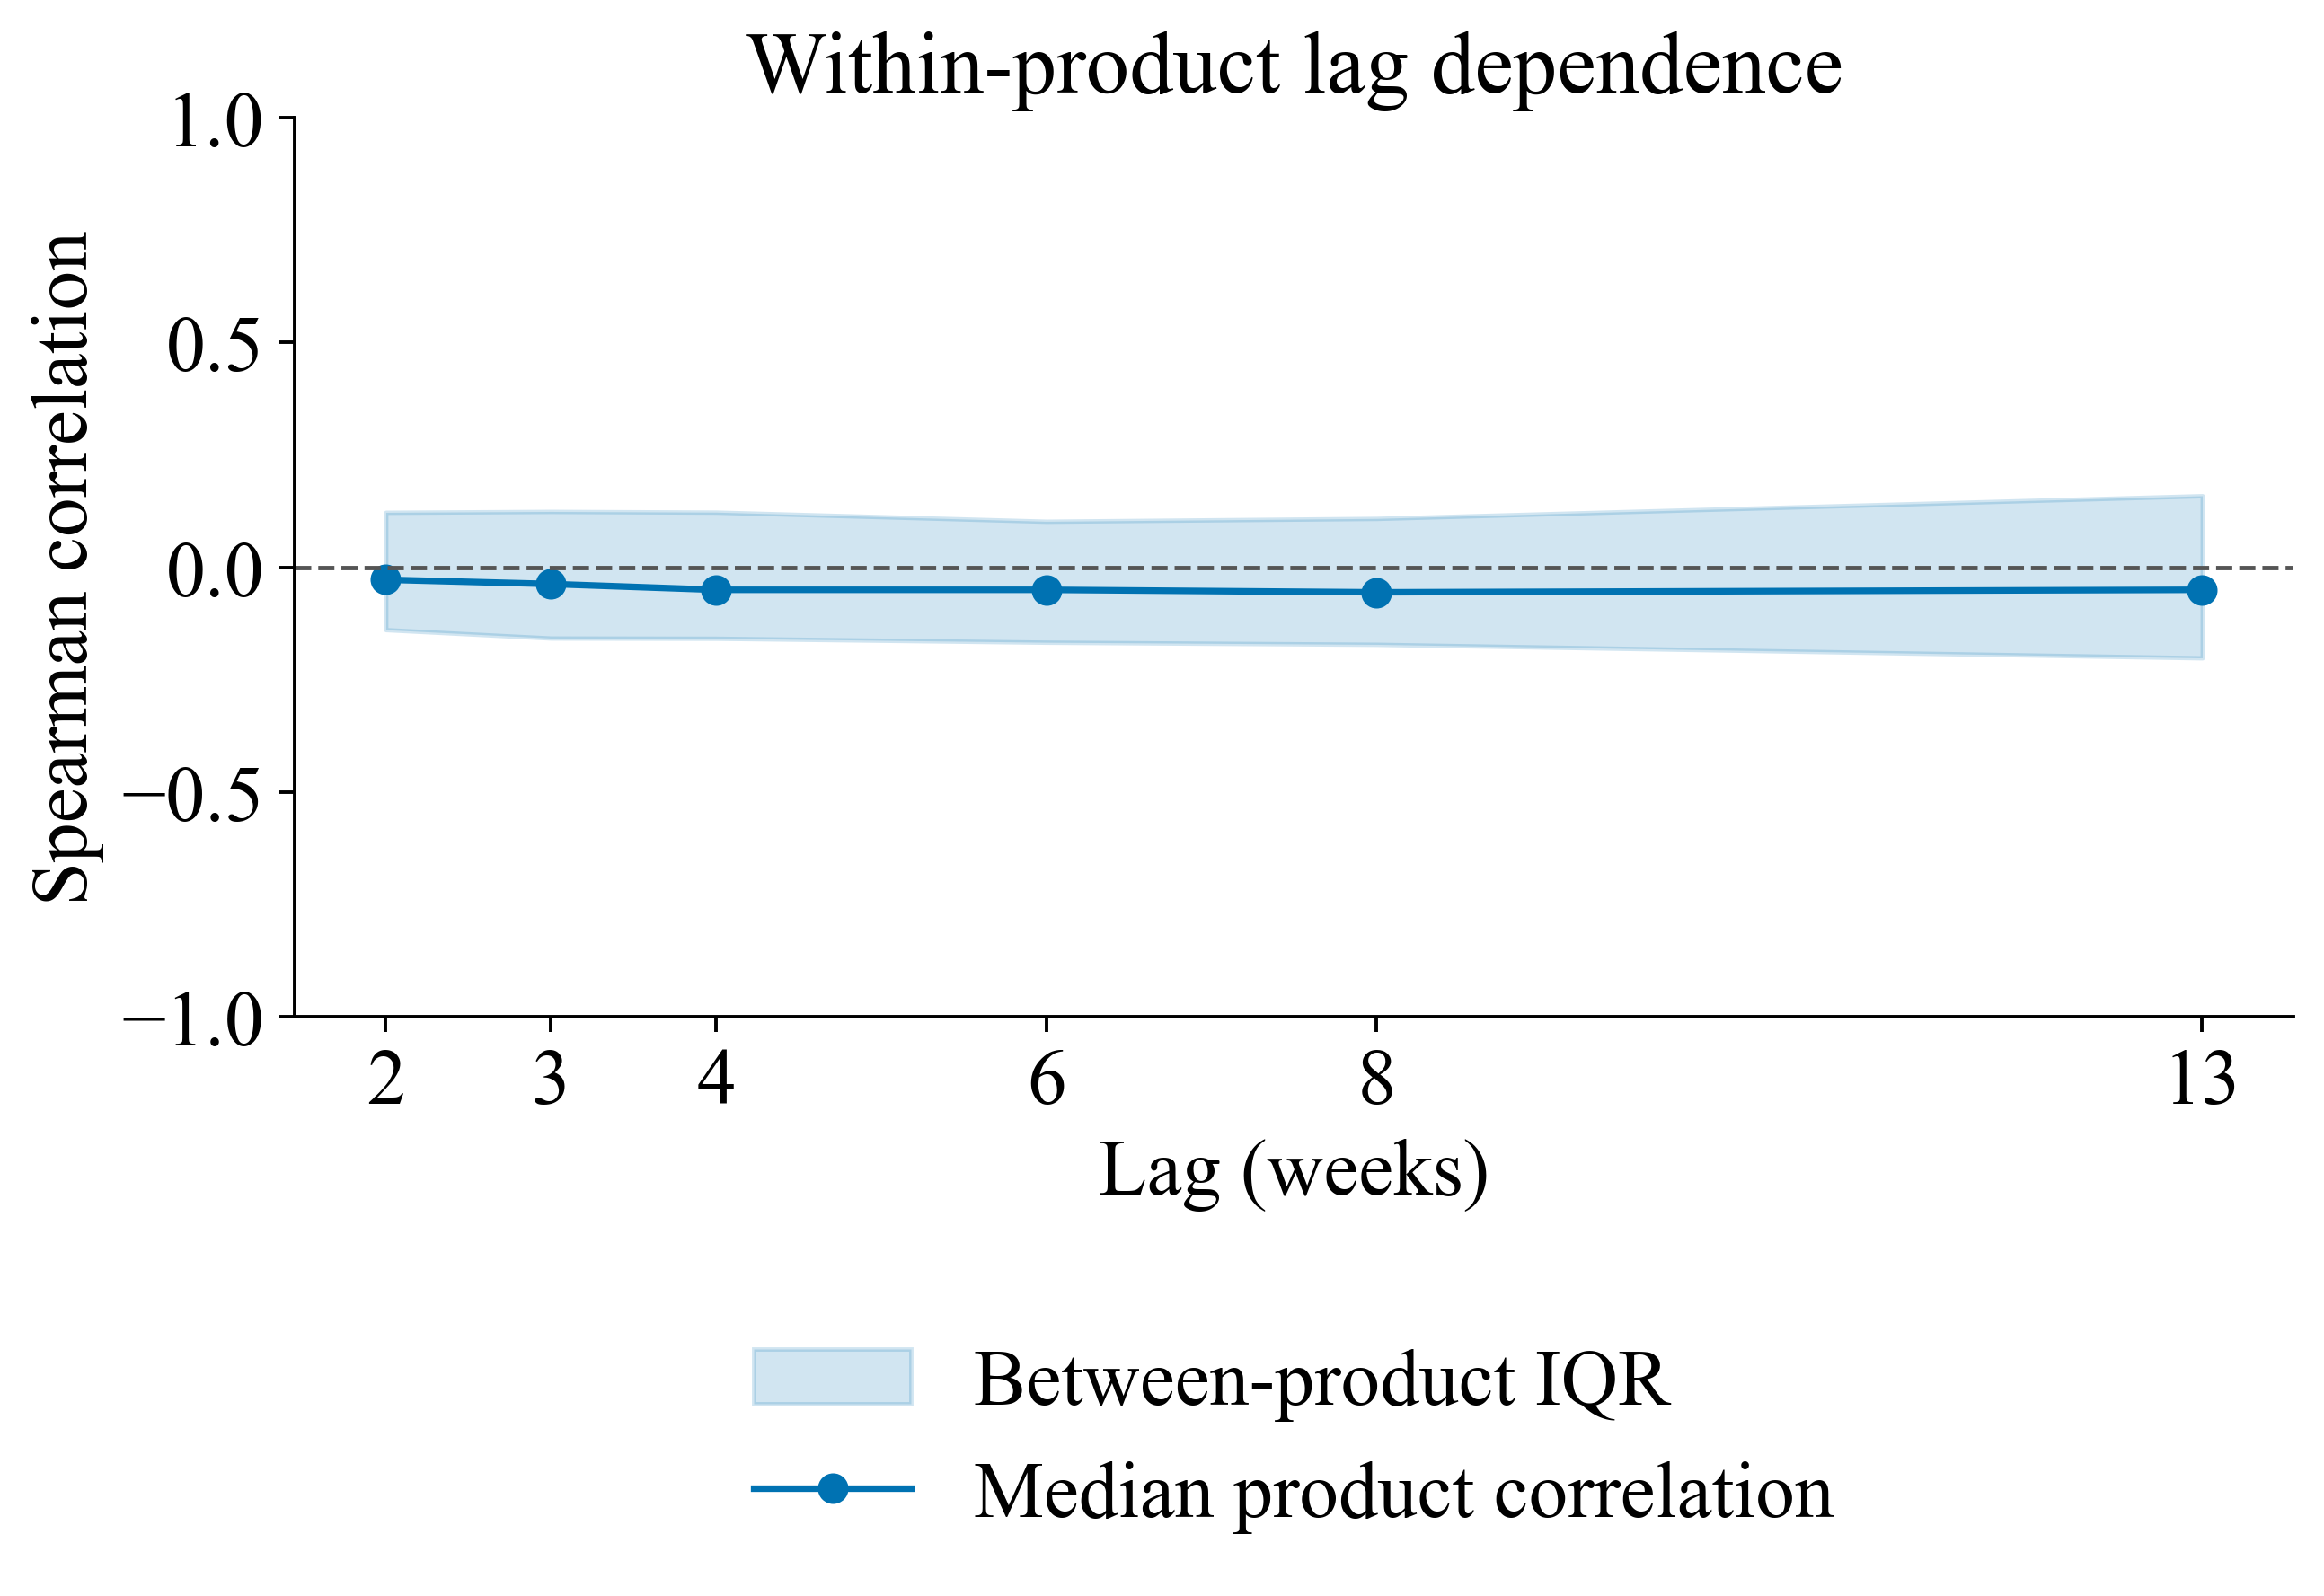

Each product contributes one training-only rank correlation when at least eight paired, nonconstant observations exist; eligible support ranges from 655 to 705 products. The shaded band is the between-product interquartile range.

In [5]:
# NB02_ASSOCIATIONS: training-only effect sizes, no feature selection
train=rows.loc[SPLIT_MASKS['Initial_W28'][0]].copy()
associations=[]
for name in FEATURES:
    part=train[['Product_Code',name,'quantity']].dropna()
    rank=part[[name,'quantity']].rank(method='average')
    centered=rank-rank.groupby(part['Product_Code']).transform('mean')
    pooled=rank[name].corr(rank['quantity']) if rank[name].std()>0 else np.nan
    within=centered[name].corr(centered['quantity']) if centered[name].std()>0 and centered['quantity'].std()>0 else np.nan
    associations.append({'Feature':name,'Paired rows':len(part),'Pooled rank r':float(pooled) if pd.notna(pooled) else 'not defined','Product-centered r':float(within) if pd.notna(within) else 'not defined'})
association_table=pd.DataFrame(associations)
for j,start in enumerate(range(0,len(association_table),16),1):
    table(association_table.iloc[start:start+16],f'training_associations_{j}')
lag_rows=[]
for lag in LAGS:
    effects=[]
    for _,block in train.groupby('Product_Code'):
        pair=block[[f'lag_{lag}','quantity']].dropna()
        if len(pair)>=8 and pair.nunique().min()>1:
            effects.append(pair.rank().corr().iloc[0,1])
    a=np.asarray(effects,dtype=float)
    lag_rows.append({'lag':lag,'eligible_products':len(a),'median':float(np.median(a)),'q25':float(np.quantile(a,.25)),'q75':float(np.quantile(a,.75))})
lag_effect=pd.DataFrame(lag_rows);lag_effect.to_csv(OUT/'lag_dependence_source.csv',index=False)
fig,ax=plt.subplots(figsize=(8.2,5.2));ax.fill_between(lag_effect['lag'],lag_effect['q25'],lag_effect['q75'],color='#0072B2',alpha=.18,label='Between-product IQR')
ax.plot(lag_effect['lag'],lag_effect['median'],'o-',color='#0072B2',label='Median product correlation')
ax.axhline(0,color='#555555',lw=1,ls='--');ax.set(xlabel='Lag (weeks)',ylabel='Spearman correlation',title='Within-product lag dependence',xticks=LAGS,ylim=(-1,1))
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.29),frameon=False,ncol=1);fig.subplots_adjust(bottom=.33)
figure(fig,'fig_uci_lag_dependence')
display(Markdown(f'Each product contributes one training-only rank correlation when at least eight paired, nonconstant observations exist; eligible support ranges from {lag_effect.eligible_products.min()} to {lag_effect.eligible_products.max()} products. The shaded band is the between-product interquartile range.'))


### Redundancy and nonlinear conditional structure

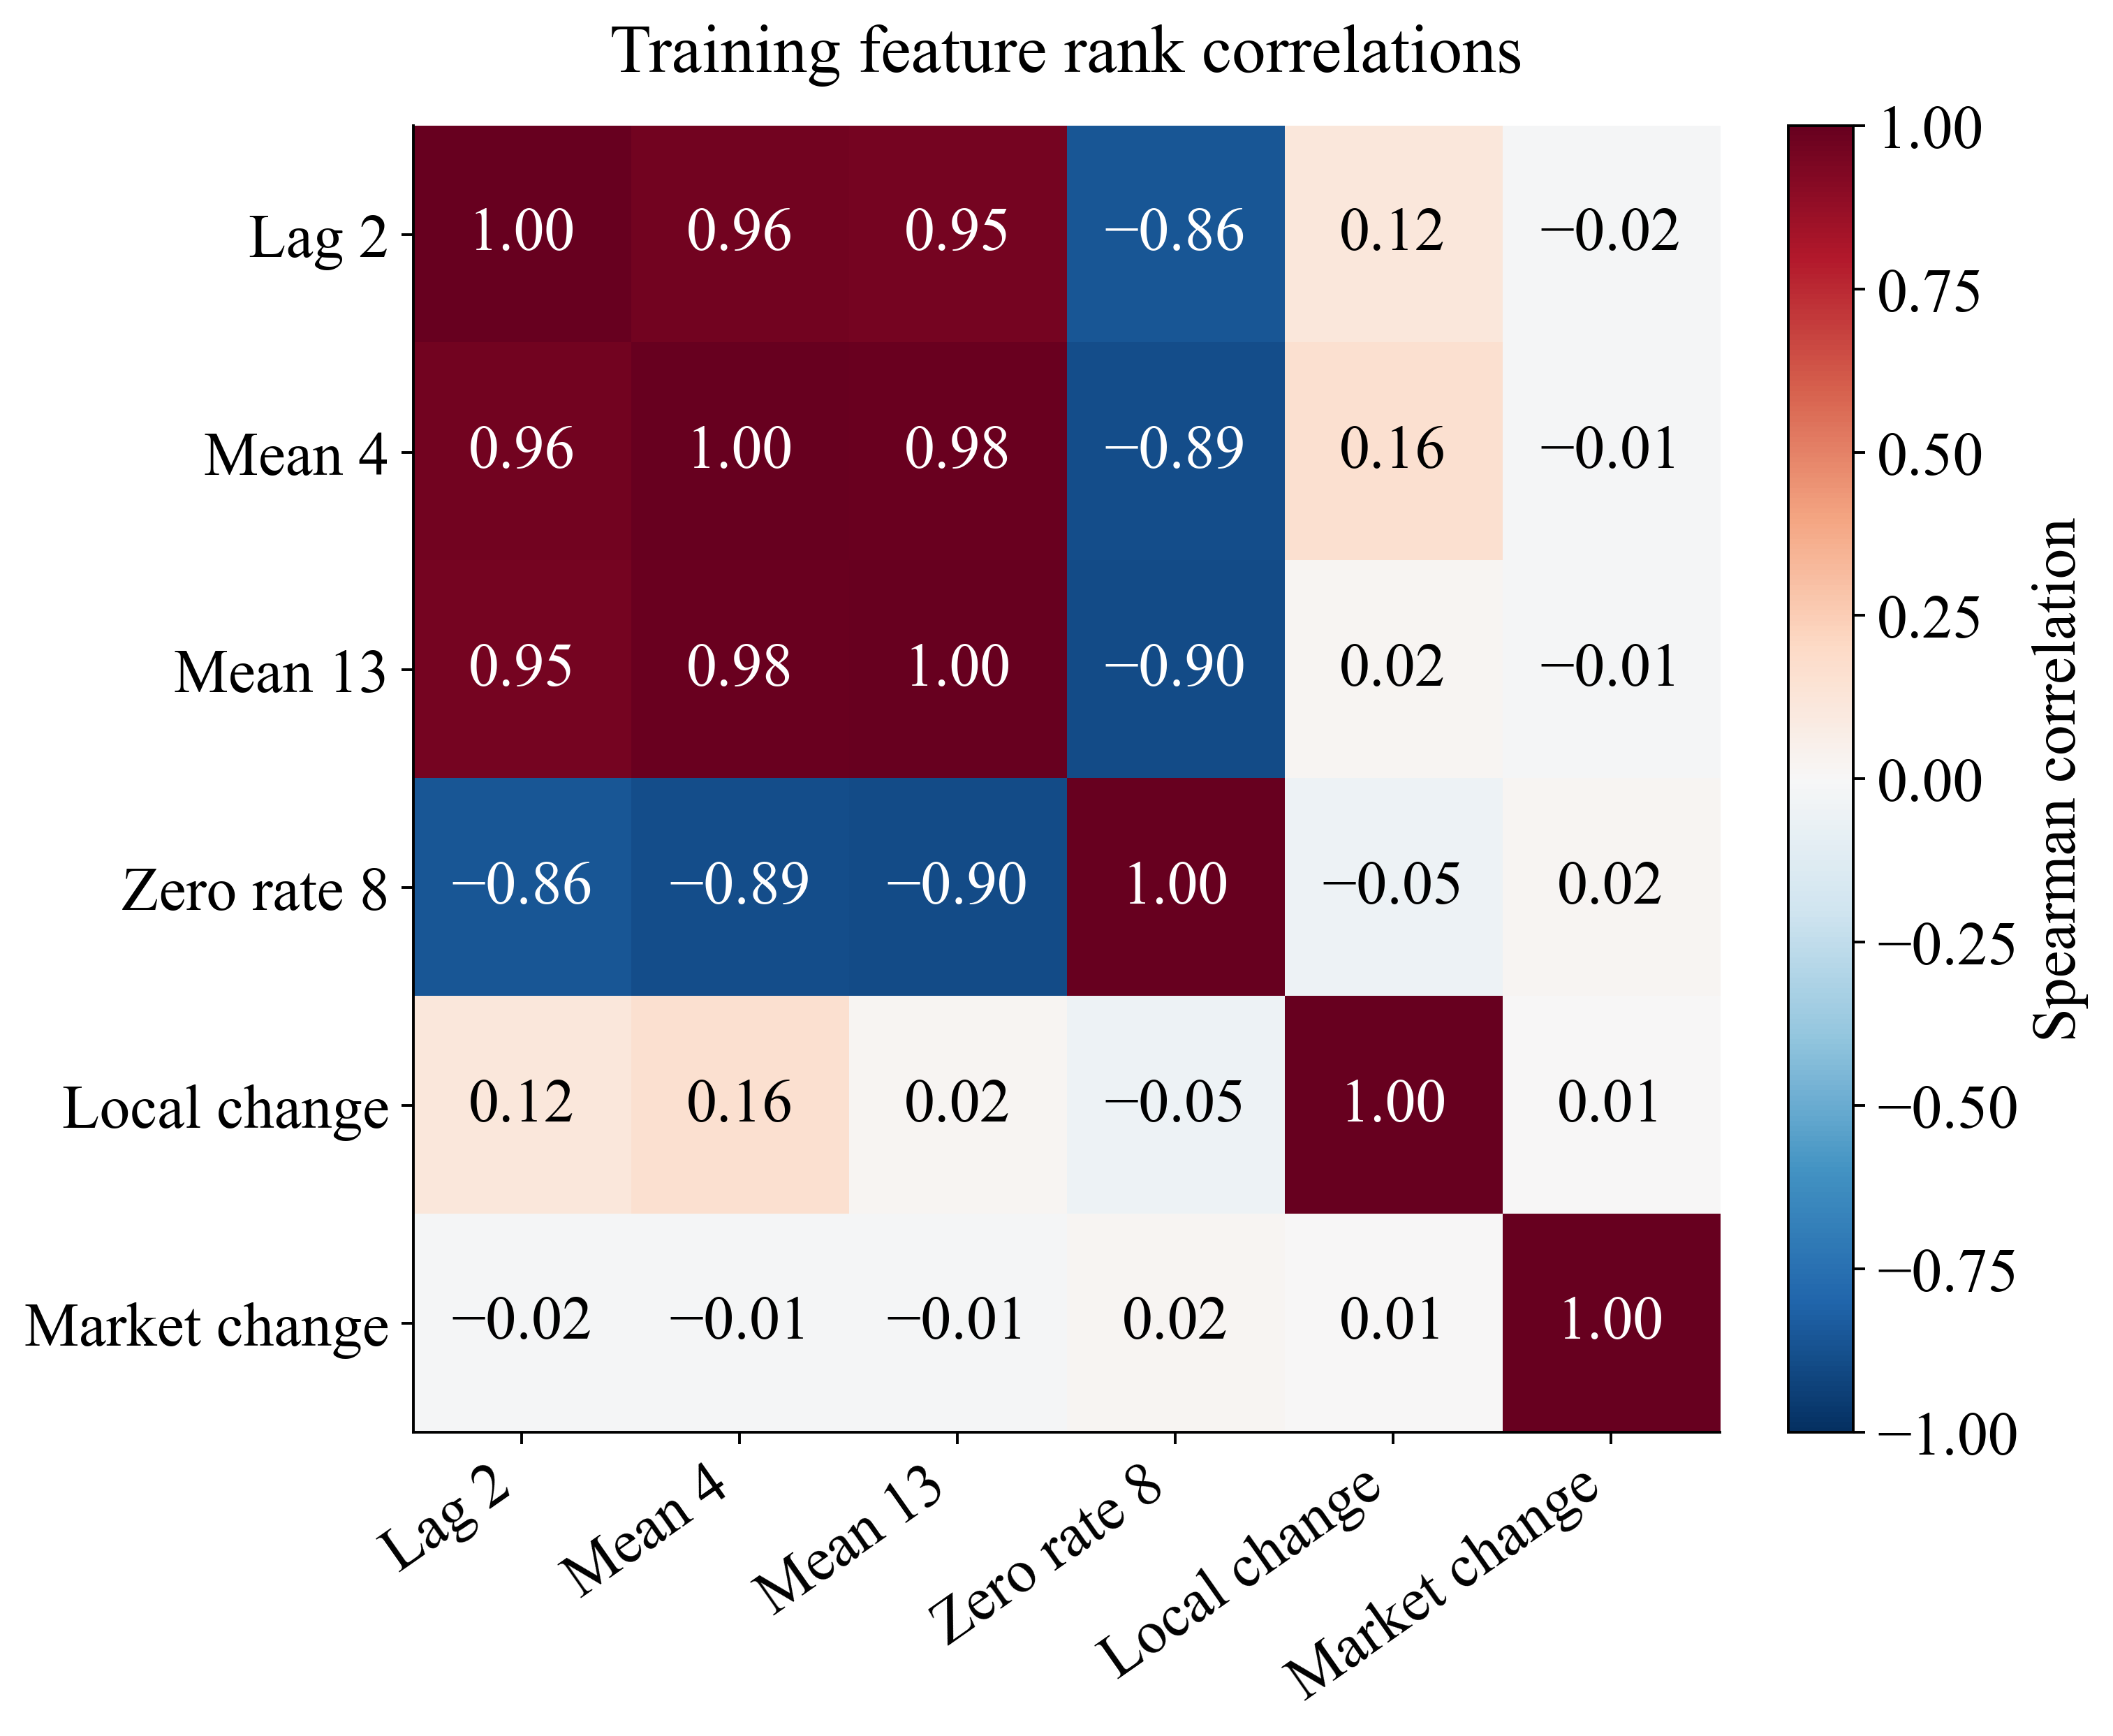

,history_level,recent_zeros,rows,mean_quantity,zero_target_fraction
0,Historical Q1,At least half,4026,0.18654,0.84501
1,Historical Q2,At least half,1326,0.55656,0.62745
2,Historical Q2,Less than half,2304,2.78082,0.13889
3,Historical Q3,Less than half,3832,7.88126,0.00705
4,Historical Q4,Less than half,3821,27.93431,0.00000


71 of 435 training feature pairs have absolute rank correlation of at least 0.95.

In [6]:
# NB02_STRUCTURE: fixed redundancy view and history-only interaction strata
focus=['lag_2','mean_4','mean_13','zero_8','short_long_change','market_change']
labels=['Lag 2','Mean 4','Mean 13','Zero rate 8','Local change','Market change']
corr=train[focus].corr(method='spearman');corr.to_csv(OUT/'redundancy_source.csv')
fig,ax=plt.subplots(figsize=(10.6,8.1));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(6),labels=labels,rotation=35,ha='right');ax.set_yticks(range(6),labels=labels)
for i in range(6):
    for j in range(6):
        v=corr.iloc[i,j];s=f'{v:.2f}'.replace('-','−')
        ax.text(j,i,s,ha='center',va='center',color='white' if abs(v)>.55 else 'black',fontsize=18)
ax.set_title('Training feature rank correlations',pad=16)
fig.colorbar(im,ax=ax,fraction=.046,pad=.04,label='Spearman correlation')
fig.subplots_adjust(left=.24,bottom=.26,right=.9,top=.92)
figure(fig,'fig_uci_redundancy')
level=pd.qcut(train['mean_8'],4,labels=False,duplicates='drop')
# Identical history levels stay together; groups may have unequal sizes.
strata=train.assign(history_level='Historical Q'+(level+1).astype(str),recent_zeros=np.where(train['zero_8']>=.5,'At least half','Less than half'))
interaction=strata.groupby(['history_level','recent_zeros'],observed=True).agg(rows=('quantity','size'),mean_quantity=('quantity','mean'),zero_target_fraction=('quantity',lambda y:float((y==0).mean()))).reset_index()
table(interaction,'history_interaction')
all_corr=train[FEATURES].corr(method='spearman').abs()
upper=np.triu(np.ones(all_corr.shape,dtype=bool),1)
redundant=int(((all_corr.to_numpy()>=.95)&upper).sum())
display(Markdown(f'{redundant} of {len(FEATURES)*(len(FEATURES)-1)//2} training feature pairs have absolute rank correlation of at least 0.95.'))


### Fold-local numerical preprocessing

In [7]:
# NB02_PREPROCESS: visible fitted transforms, fold-specific scope and perturbation proof
COUNT_FEATURES=[f'lag_{k}' for k in LAGS]+[f'{kind}_{w}' for w in WINDOWS for kind in ['mean','std']]+['positive_mean_8','max_8','history_mean','history_std','market_mean_4','market_mean_13']
MISSING_FEATURES=[f'lag_{k}' for k in LAGS]
class FoldPreprocessor:
    """Fixed feature transformations with medians/scales learned only on fit rows."""
    def fixed(self, frame):
        a=frame[FEATURES].astype(float).copy()
        assert not np.isinf(a.to_numpy()).any()
        assert (a[COUNT_FEATURES].ge(0) | a[COUNT_FEATURES].isna()).all().all()
        a[COUNT_FEATURES]=np.log1p(a[COUNT_FEATURES])
        return a
    def fit(self, frame):
        a=self.fixed(frame)
        self.median=a.median();assert self.median.notna().all()
        filled=a.fillna(self.median)
        self.scale=filled.quantile(.75)-filled.quantile(.25)
        self.scale=self.scale.where(self.scale>0,1.)
        self.fit_row_ids=frame['row_id'].tolist()
        return self
    def transform(self, frame):
        a=self.fixed(frame); z=(a.fillna(self.median)-self.median)/self.scale
        for name in MISSING_FEATURES:z[name+'_missing']=a[name].isna().astype(float)
        out=z.to_numpy(dtype=np.float64)
        assert np.isfinite(out).all()
        return out
    def parameters(self):
        return {'features':FEATURES,'log1p_features':COUNT_FEATURES,'missing_indicators':MISSING_FEATURES,'median':self.median.to_dict(),'scale':self.scale.to_dict(),'fit_row_ids':self.fit_row_ids}
TRANSFORMERS={}; dimensional=[]
for stage,(fit_mask,eval_mask) in SPLIT_MASKS.items():
    fitting=rows.loc[fit_mask]; evaluating=rows.loc[eval_mask]
    transform=FoldPreprocessor().fit(fitting)
    a=transform.transform(fitting); b=transform.transform(evaluating)
    TRANSFORMERS[stage]=transform
    dump(OUT/f'preprocessor_{stage}.json',transform.parameters())
    np.savez_compressed(OUT/f'transformed_{stage}.npz',fit_X=a,evaluation_X=b,fit_row_id=fitting.row_id.to_numpy(dtype=str),evaluation_row_id=evaluating.row_id.to_numpy(dtype=str))
    before=json.dumps(transform.parameters(),sort_keys=True)
    altered=evaluating.copy();altered[COUNT_FEATURES]=altered[COUNT_FEATURES]*100+1000
    transform.transform(altered)
    assert json.dumps(transform.parameters(),sort_keys=True)==before
    assert set(transform.fit_row_ids).isdisjoint(evaluating.row_id)
    dimensional.append({'Stage':stage,'Fit rows':len(a),'Forecast rows':len(b),'Raw predictors':len(FEATURES),'Processed predictors':a.shape[1],'Latest fit label':int(fitting.week.max()),'Finite outputs':bool(np.isfinite(a).all() and np.isfinite(b).all())})
table(pd.DataFrame(dimensional),'preprocessing_dimensions')


,Stage,Fit rows,Forecast rows,Raw predictors,Processed predictors,Latest fit label,Finite outputs
0,F1,9477,2916,30,36,18,True
1,F2,12393,2916,30,36,22,True
2,Initial_W28,15309,8019,30,36,26,True


In [8]:
# NB02_FEATURE_MANIFEST: feature lists and preprocessor files read by the later notebooks
FEATURE_MANIFEST={'run_id':RUN_ID,'raw_features_sha256':sha(raw_path),'split_ids_sha256':sha(BASE/'Data/feature_split_ids.parquet'),
 'rows':len(rows),'core_products':729,'raw_predictors':len(FEATURES),'processed_predictors':len(FEATURES)+len(MISSING_FEATURES),
 'features':FEATURES,'count_features':COUNT_FEATURES,'missing_indicator_features':MISSING_FEATURES,'origins':[6,38],
 'information_cutoff_offset':-2,'initial_oof_latest_label':26,'pending_oof_week':27,
 'preprocessor_files':{k:{'path':str((OUT/f'preprocessor_{k}.json').relative_to(ROOT)),'sha256':sha(OUT/f'preprocessor_{k}.json')} for k in TRANSFORMERS}}
dump(BASE/'Manifests/feature_manifest.json',FEATURE_MANIFEST)
latest=json.loads((BASE/'Manifests/latest_runs.json').read_text());latest['NB02']=RUN_ID;dump(BASE/'Manifests/latest_runs.json',latest)


# Part C · M5 (Walmart) weekly item-store sales

## Causal weekly features and fold-local preprocessing

In [1]:
# NB02_SETUP: paths, feature configuration and helpers (same conventions as Part B)
import os
os.environ['OMP_NUM_THREADS']='4';os.environ['OPENBLAS_NUM_THREADS']='4'
import json,hashlib,time,resource,gzip,inspect,warnings,io,csv,zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import cloudpickle
from IPython.display import display,Markdown,Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits,threadpool_info
from scipy import special,stats
THREAD_LIMIT=threadpool_limits(limits=4)
SEED=2026
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'m5'
RUN_ID='NB02_M5_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ');OUT=BASE/'Artifacts'/RUN_ID;OUT.mkdir(parents=True,exist_ok=True)
for sub in 'Configs Data Manifests'.split():(BASE/sub).mkdir(parents=True,exist_ok=True)
def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
def dump(p,v):p.write_text(json.dumps(v,indent=2,allow_nan=False,default=str))
FONT=font_manager.findfont('Times New Roman',fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False,'mathtext.fontset':'custom','mathtext.rm':'Times New Roman','mathtext.it':'Times New Roman:italic','mathtext.bf':'Times New Roman:bold','mathtext.default':'regular'})
PALETTE=['#0072B2','#E69F00','#009E73','#D55E00','#CC79A7','#56B4E9','#000000']  # Okabe-Ito, colour-blind safe
pd.set_option('display.max_rows',200,'display.max_columns',20,'display.max_colwidth',None,'display.width',220,'display.float_format',lambda v:f'{v:.5f}')
def tidy(df,note='n/a'):
    """Display copy of a table: missing cells are marked explicitly instead of NaN; underflowed p-values are shown as bounds."""
    out=df.copy()
    for c in out.columns:
        if str(c)=='p' or str(c).startswith('p ') or 'p-value' in str(c) or str(c).startswith('Holm p'):
            out[c]=['< 1e-300' if (isinstance(v,float) and v==0.0) else (f'{v:.4g}' if isinstance(v,(float,np.floating)) else v) for v in out[c]]
    return out.astype(object).where(out.notna(),note)
def table(df,name,best=None,fmt='%.5f'):
    clean=tidy(df.reset_index() if df.index.name is not None else df)
    clean.to_csv(OUT/(name+'.csv'),index=False);(OUT/(name+'.tex')).write_text(clean.to_latex(index=False,float_format=fmt,escape=True))
    if best:display(clean.style.format({k:(lambda v:(fmt%v) if isinstance(v,(float,np.floating)) else v) for k in best}).highlight_min(subset=best,props='font-weight:bold;'))
    else:display(clean)
def figure(fig,name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig);display(Image(filename=str(OUT/(name+'.png')),width=900))
def label_panels(axes,labels='abcdefgh'):
    """Letter each panel below its x-axis label, (a), (b), ..., so that panels can be cited."""
    for ax,l in zip(np.ravel(axes),labels):ax.set_xlabel((ax.get_xlabel()+'\n' if ax.get_xlabel() else '')+f'({l})')
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all()
    positive=y>0;zero=~positive;den=np.abs(y)+np.abs(p);sm=np.divide(2*np.abs(y-p),den,out=np.zeros(len(y)),where=den>0)
    return {'RMSPE':float(np.sqrt(np.mean(((p[positive]-y[positive])/y[positive])**2))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'sMAPE_pct':float(100*sm.mean()),'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
def rmspe(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);m=y>0;return float(np.sqrt(np.mean(((p[m]-y[m])/y[m])**2)))
CONTRACT={'first_origin':136,'last_permitted_origin':263,'lags':[2,3,4,6,8,13],'rolling_windows':[4,8,13],'latest_outcome_offset':-2,'fit_window_weeks':104,'market_context':'core-only store-level and department-level means with the same t-2 cutoff','planned_covariates':['price','price_ratio_4','price_missing','snap_days','event_days'],'categorical_one_hot':['store_id','dept_id','cat_id','state_id'],'identifiers_as_predictors':False,'preprocessing':'fixed log1p of count magnitudes, fit-window median imputation, median/IQR scaling; zero IQR uses one; fixed lag missingness indicators; one-hot indicators pass unchanged','feature_selection':'none','outlier_clipping':False,'outcome_based_exclusions':False,'primary_metric':'RMSPE on y>0 with explicit positive support; all-row RMSE/MAE and zero-demand metrics required'}
dump(BASE/'Configs/feature_contract.json',CONTRACT)
DESIGN=json.loads((BASE/'Configs/study_design.json').read_text());FOLDS=json.loads((BASE/'Configs/inner_folds.json').read_text())
RAW=ROOT/'dataset'/'raw'/'m5'/'m5-forecasting-accuracy.zip'


### Planned covariates: prices, SNAP days and events per week

In [2]:
# NB02_COVARIATES: weekly price, SNAP and event covariates (known at the forecast date)
wide=pd.read_parquet(BASE/'Data/core_permitted_wide.parquet');wide.columns=[int(c) for c in wide.columns];CORE_IDS=wide.index.tolist()
alloc=pd.read_csv(BASE/'Configs/series_allocation.csv').set_index('id');meta=alloc.loc[CORE_IDS,['item_id','dept_id','cat_id','store_id','state_id']]
cal=pd.read_parquet(BASE/'Data/calendar_weeks.parquet');weeks_tab=pd.read_csv(BASE/'Configs/week_index.csv');WK=dict(zip(weeks_tab.wm_yr_wk,weeks_tab.week));LAST=CONTRACT['last_permitted_origin']
calw=cal.dropna(subset=['week']).copy();calw['week']=calw.week.astype(int);calw['event']=calw.event_name_1.notna().astype(int)+calw.event_name_2.notna().astype(int)
wk_cov=calw.groupby('week').agg(event_days=('event',lambda s:int((s>0).sum())),snap_CA=('snap_CA','sum'),snap_TX=('snap_TX','sum'),snap_WI=('snap_WI','sum'))
with zipfile.ZipFile(RAW) as z:
    with z.open('sell_prices.csv') as f:prices=pd.read_csv(f,dtype={'store_id':'category','item_id':'category','wm_yr_wk':'int32','sell_price':'float32'})
prices['week']=prices.wm_yr_wk.map(WK);prices=prices.dropna(subset=['week']);prices['week']=prices.week.astype(int);prices=prices[prices.week<=LAST]
prices['id']=prices.item_id.astype(str)+'_'+prices.store_id.astype(str)+'_evaluation';price_wide=prices.pivot(index='id',columns='week',values='sell_price').reindex(index=CORE_IDS,columns=range(LAST+1))
PRICE=price_wide.to_numpy(np.float32);PRICE_MISSING=np.isnan(PRICE).astype(np.float32);PRICE_FILLED=pd.DataFrame(PRICE).ffill(axis=1).bfill(axis=1).to_numpy(np.float32);assert np.isfinite(PRICE_FILLED).all()
state_snap={'CA':wk_cov.snap_CA,'TX':wk_cov.snap_TX,'WI':wk_cov.snap_WI}
cov_summary=pd.DataFrame([{'Covariate':'price (weekly sell price, filled forward/backward where the item is not offered)','Rows':int(PRICE.size),'Missing share before filling':float(PRICE_MISSING.mean())},{'Covariate':'event_days (days with a calendar event in the week)','Rows':len(wk_cov),'Missing share before filling':0.0},{'Covariate':'snap_days (SNAP days of the state in the week)','Rows':len(wk_cov),'Missing share before filling':0.0}])
table(cov_summary,'covariates')
print(f'{len(CORE_IDS):,} core series; prices mapped for weeks 0–{LAST}; {len(wk_cov)} weeks of calendar covariates.')

,Covariate,Rows,Missing share before filling
0,"price (weekly sell price, filled forward/backward where the item is not offered)",7244424,0.21763
1,event_days (days with a calendar event in the week),277,0.00000
2,snap_days (SNAP days of the state in the week),277,0.00000


27,441 core series; prices mapped for weeks 0–263; 277 weeks of calendar covariates.


### Information set and fixed feature construction

In [3]:
# NB02_FEATURES: visible causal construction, no full-series statistics
LAGS=CONTRACT['lags'];WINDOWS=CONTRACT['rolling_windows']
STORES=sorted(meta.store_id.unique());DEPTS=sorted(meta.dept_id.unique());CATS=sorted(meta.cat_id.unique());STATES=sorted(meta.state_id.unique())
store_idx=np.unique(meta.store_id.to_numpy(),return_inverse=True)[1];dept_idx=np.unique(meta.dept_id.to_numpy(),return_inverse=True)[1]
def group_mean(h,idx,n):
    """Mean over core series of each group (store or department), per column."""
    s=np.zeros((n,h.shape[1]));np.add.at(s,idx,h);c=np.bincount(idx,minlength=n)[:,None];return s/np.maximum(c,1)
def build_features(history,origins,market_history,meta_,price_filled,price_missing,wk_cov_,state_snap_):
    """Use only outcome columns through origin minus two and the planned covariates of the origin week; never receive current labels."""
    history=history.sort_index();market_history=market_history.sort_index();frames=[]
    m_store=np.unique(meta_.store_id.to_numpy(),return_inverse=True)[1];m_dept=np.unique(meta_.dept_id.to_numpy(),return_inverse=True)[1]
    c_store=np.unique(market_history.index.map(lambda i:i.rsplit('_',3)[-3]+'_'+i.rsplit('_',3)[-2]).to_numpy(),return_inverse=True);c_dept=np.unique(market_history.index.map(lambda i:'_'.join(i.split('_')[:2])).to_numpy(),return_inverse=True)
    for origin in origins:
        cutoff=origin-2;assert set(range(cutoff+1)).issubset(history.columns)
        h=history.loc[:,list(range(cutoff+1))].to_numpy(dtype=float);mh=market_history.loc[:,list(range(cutoff+1))].to_numpy(dtype=float);f=pd.DataFrame(index=history.index)
        for lag in LAGS:f[f'lag_{lag}']=history[origin-lag].astype(float) if origin-lag>=0 else np.nan
        for window in WINDOWS:
            recent=h[:,-window:];f[f'mean_{window}']=recent.mean(axis=1);f[f'std_{window}']=recent.std(axis=1,ddof=0);f[f'zero_{window}']=(recent==0).mean(axis=1)
        recent=h[:,-8:];positive=(recent>0).sum(axis=1);f['positive_mean_8']=np.divide(recent.sum(axis=1),positive,out=np.zeros(len(f)),where=positive>0);f['max_8']=recent.max(axis=1)
        f['history_mean']=h.mean(axis=1);f['history_std']=h.std(axis=1,ddof=0);f['history_zero']=(h==0).mean(axis=1)
        last_positive=np.where(h>0,np.arange(h.shape[1]),-1).max(axis=1);f['positive_age']=np.where(last_positive>=0,cutoff-last_positive,h.shape[1]+1);f['ever_positive']=(last_positive>=0).astype(float)
        f['history_length']=h.shape[1];f['week_index']=origin;f['short_long_change']=(f['mean_4']-f['mean_13'])/(1+f['mean_13']);f['recent_level_change']=(f['lag_2']-f['mean_8'])/(1+f['mean_8'])
        sm=group_mean(mh[:,-13:],c_store[1],len(c_store[0]));dm=group_mean(mh[:,-13:],c_dept[1],len(c_dept[0]))
        s_of=np.searchsorted(c_store[0],meta_.store_id.to_numpy());d_of=np.searchsorted(c_dept[0],meta_.dept_id.to_numpy())
        f['store_mean_4']=sm[s_of][:,-4:].mean(1);f['store_mean_13']=sm[s_of].mean(1);f['store_zero_4']=(group_mean((mh[:,-4:]==0).astype(float),c_store[1],len(c_store[0]))[s_of]).mean(1);f['store_change']=(f['store_mean_4']-f['store_mean_13'])/(1+f['store_mean_13'])
        f['dept_mean_4']=dm[d_of][:,-4:].mean(1);f['dept_mean_13']=dm[d_of].mean(1);f['dept_change']=(f['dept_mean_4']-f['dept_mean_13'])/(1+f['dept_mean_13'])
        f['price']=price_filled[:,origin];prev=price_filled[:,max(0,origin-4):origin].mean(1);f['price_ratio_4']=price_filled[:,origin]/np.maximum(prev,1e-6);f['price_missing']=price_missing[:,origin]
        f['snap_days']=[float(state_snap_[s].loc[origin]) for s in meta_.state_id.to_numpy()] if False else np.array([state_snap_[s].loc[origin] for s in STATES])[np.searchsorted(STATES,meta_.state_id.to_numpy())].astype(float)
        f['event_days']=float(wk_cov_.event_days.loc[origin])
        f.insert(0,'week',origin);f.insert(0,'id',history.index);frames.append(f.reset_index(drop=True))
    return pd.concat(frames,ignore_index=True)
def one_hot(meta_):
    cols={}
    for name,levels in [('store_id',STORES),('dept_id',DEPTS),('cat_id',CATS),('state_id',STATES)]:
        for lv in levels:cols[f'{name}={lv}']=(meta_[name].to_numpy()==lv).astype(np.float32)
    return pd.DataFrame(cols)
FEATURE_START=time.perf_counter();ORIGINS=range(CONTRACT['first_origin'],LAST+1)
X=build_features(wide,ORIGINS,wide,meta,PRICE_FILLED,PRICE_MISSING,wk_cov,state_snap);FEATURE_SECONDS=time.perf_counter()-FEATURE_START
FEATURES=[c for c in X if c not in ('id','week')];oh=one_hot(meta.loc[X.id].reset_index(drop=True));ONE_HOT=list(oh.columns);X=pd.concat([X,oh],axis=1)
long=wide.reset_index().melt(id_vars='id',var_name='week',value_name='quantity');long['week']=long.week.astype(int)
rows=X.merge(long,on=['id','week'],validate='one_to_one');rows.insert(0,'row_id',rows.id+'::W'+rows.week.astype(str));assert rows.row_id.is_unique and len(rows)==len(CORE_IDS)*len(ORIGINS)
for c in FEATURES:rows[c]=rows[c].astype(np.float32)
missing=rows[FEATURES].isna().sum();assert np.isinf(rows[FEATURES].to_numpy(np.float32)).sum()==0 and set(missing[missing>0].index)<=set()
raw_path=BASE/'Data/causal_features_core.parquet';rows.to_parquet(raw_path,index=False)
table(pd.DataFrame([{'Feature group':g,'Predictors':n,'Latest information':e} for g,n,e in [('Series lag quantities',len(LAGS),'t − 2 or earlier'),('Rolling moments and zero fractions',3*len(WINDOWS),'t − 2'),('Positive-demand, extreme and expanding history',8,'t − 2'),('Known week index',1,'known'),('Relative level changes',2,'t − 2'),('Store and department market context (core-only)',7,'t − 2'),('Planned covariates: price, price ratio, price missing, SNAP days, event days',5,'week t, known in advance'),('One-hot store, department, category, state',len(ONE_HOT),'fixed')]]),'feature_groups')
display(Markdown(f'{len(rows):,} series–week rows (origins W{ORIGINS.start}–W{LAST}), {len(FEATURES)} numeric predictors and {len(ONE_HOT)} indicators; all {len(CORE_IDS):,} core series are retained.'))

,Feature group,Predictors,Latest information
0,Series lag quantities,6,t − 2 or earlier
1,Rolling moments and zero fractions,9,t − 2
2,"Positive-demand, extreme and expanding history",8,t − 2
3,Known week index,1,known
4,Relative level changes,2,t − 2
5,Store and department market context (core-only),7,t − 2
6,"Planned covariates: price, price ratio, price missing, SNAP days, event days",5,"week t, known in advance"
7,"One-hot store, department, category, state",23,fixed


3,512,448 series–week rows (origins W136–W263), 38 numeric predictors and 23 indicators; all 27,441 core series are retained.

### Causality and alignment checks

In [4]:
# NB02_CAUSALITY: prefix, delayed-label, isolation and alignment assertions on a subset of origins and series
checks=[];sub=wide.iloc[:300];sub_meta=meta.loc[sub.index];g=np.random.default_rng(SEED)
for origin in [136,180,240,263]:
    full=build_features(sub,[origin],wide,sub_meta,PRICE_FILLED[:300],PRICE_MISSING[:300],wk_cov,state_snap)
    tampered=sub.copy();tampered.loc[:,list(range(origin-1,LAST+1))]=g.integers(0,50,(len(sub),LAST+2-origin));prefix=build_features(tampered,[origin],wide,sub_meta,PRICE_FILLED[:300],PRICE_MISSING[:300],wk_cov,state_snap)
    checks.append({'Origin':origin,'Case':'outcomes from t-1 onward replaced','Features unchanged':bool(np.allclose(full[FEATURES].to_numpy(float),prefix[FEATURES].to_numpy(float),equal_nan=True))})
    shifted=sub.copy();shifted[origin-2]=shifted[origin-2]+7;delayed=build_features(shifted,[origin],wide,sub_meta,PRICE_FILLED[:300],PRICE_MISSING[:300],wk_cov,state_snap)
    checks.append({'Origin':origin,'Case':'outcome at t-2 perturbed','Features unchanged':bool(np.allclose(full[FEATURES].to_numpy(float),delayed[FEATURES].to_numpy(float),equal_nan=True))})
    other=sub.copy();other.iloc[1,:]=other.iloc[1,:]*3+2;iso=build_features(other,[origin],wide,sub_meta,PRICE_FILLED[:300],PRICE_MISSING[:300],wk_cov,state_snap)
    own=[c for c in FEATURES if not c.startswith(('store_','dept_','price','snap','event','week_index'))]
    checks.append({'Origin':origin,'Case':'another series perturbed (own features of series 0)','Features unchanged':bool(np.allclose(full.loc[full.id==sub.index[0],own].to_numpy(float),iso.loc[iso.id==sub.index[0],own].to_numpy(float),equal_nan=True))})
    checks.append({'Origin':origin,'Case':'label alignment (lag_2 equals the outcome of week t-2)','Features unchanged':bool(np.array_equal(full['lag_2'].to_numpy(float),sub[origin-2].to_numpy(float)))})
checks=pd.DataFrame(checks);table(checks,'causality_checks');assert checks.loc[checks.Case.str.startswith('outcomes from'),'Features unchanged'].all() and (~checks.loc[checks.Case.str.startswith('outcome at t-2'),'Features unchanged']).all() and checks.loc[checks.Case.str.startswith(('another','label')),'Features unchanged'].all()


,Origin,Case,Features unchanged
0,136,outcomes from t-1 onward replaced,True
1,136,outcome at t-2 perturbed,False
2,136,another series perturbed (own features of series 0),True
3,136,label alignment (lag_2 equals the outcome of week t-2),True
4,180,outcomes from t-1 onward replaced,True
5,180,outcome at t-2 perturbed,False
6,180,another series perturbed (own features of series 0),True
7,180,label alignment (lag_2 equals the outcome of week t-2),True
8,240,outcomes from t-1 onward replaced,True
9,240,outcome at t-2 perturbed,False


### Exact folds, row identities and the pending week

In [5]:
# NB02_SPLITS: exact fit/evaluation row identities and release timing
STAGES={**{k:(v['fit_latest_week'],tuple(v['evaluation_weeks'])) for k,v in DESIGN['stages'].items()}};FITW=CONTRACT['fit_window_weeks'];SPLIT_MASKS={};split_summary=[];records=[]
for stage,(last,bounds) in STAGES.items():
    fit=rows.week.between(last-FITW+1,last);ev=rows.week.between(*bounds);assert not (fit&ev).any() and rows.loc[fit,'week'].max()<=rows.loc[ev,'week'].min()-2
    SPLIT_MASKS[stage]=(fit,ev);split_summary.append({'Stage':stage,'Fit weeks':f'W{last-FITW+1}–W{last}','Fit rows':int(fit.sum()),'Forecast weeks':f'W{bounds[0]}–W{bounds[1]}','Forecast rows':int(ev.sum()),'Labels usable at W253':int((ev&(rows.week<=251)).sum())})
    for role,mask in [('fit',fit),('forecast',ev)]:
        b=rows.loc[mask,['row_id','id','week']].copy();b['stage']=stage;b['role']=role;b['label_release_origin']=b.week+2;records.append(b)
pd.concat(records,ignore_index=True).to_parquet(BASE/'Data/feature_split_ids.parquet',index=False);table(pd.DataFrame(split_summary),'exact_fold_dimensions')

,Stage,Fit weeks,Fit rows,Forecast weeks,Forecast rows,Labels usable at W253
0,F0,W136–W239,2853864,W241–W243,82323,82323
1,F1,W140–W243,2853864,W245–W248,109764,109764
2,F2,W144–W247,2853864,W249–W252,109764,82323
3,Initial,W148–W251,2853864,W253–W263,301851,0


### Fold-local numerical preprocessing

In [6]:
# NB02_PREPROCESS: fitted transforms per stage, perturbation proof
COUNT_FEATURES=[f'lag_{k}' for k in LAGS]+[f'{kind}_{w}' for w in WINDOWS for kind in ['mean','std']]+['positive_mean_8','max_8','history_mean','history_std','store_mean_4','store_mean_13','dept_mean_4','dept_mean_13','price']
MISSING_FEATURES=[f'lag_{k}' for k in LAGS];NAMES=FEATURES+[f'{x}_missing' for x in MISSING_FEATURES]+ONE_HOT
class FoldPreprocessor:
    def fixed(self,frame):
        a=frame[FEATURES].astype(float).copy();assert (a[COUNT_FEATURES].ge(0)|a[COUNT_FEATURES].isna()).all().all();a[COUNT_FEATURES]=np.log1p(a[COUNT_FEATURES]);return a
    def fit(self,frame):
        a=self.fixed(frame);self.median=a.median();assert self.median.notna().all();b=a.fillna(self.median);self.scale=(b.quantile(.75)-b.quantile(.25));self.scale=self.scale.where(self.scale>0,1.);self.fit_rows=len(frame);return self
    def transform(self,frame):
        a=self.fixed(frame);z=(a.fillna(self.median)-self.median)/self.scale
        for k in MISSING_FEATURES:z[k+'_missing']=a[k].isna().astype(float)
        z[ONE_HOT]=frame[ONE_HOT].to_numpy(np.float32);out=z[NAMES];assert np.isfinite(out.to_numpy()).all();return out
    def parameters(self):return {'features':FEATURES,'log1p_features':COUNT_FEATURES,'missing_indicators':MISSING_FEATURES,'one_hot':ONE_HOT,'median':self.median.to_dict(),'scale':self.scale.to_dict(),'fit_rows':self.fit_rows}
dimensional=[]
for stage,(fit_mask,eval_mask) in SPLIT_MASKS.items():
    fitting=rows.loc[fit_mask];evaluating=rows.loc[eval_mask];tr=FoldPreprocessor().fit(fitting);a=tr.transform(fitting.head(2000));b=tr.transform(evaluating.head(2000))
    dump(OUT/f'preprocessor_{stage}.json',tr.parameters());before=json.dumps(tr.parameters(),sort_keys=True);altered=evaluating.head(2000).copy();altered[COUNT_FEATURES]=altered[COUNT_FEATURES]*100+1000;tr.transform(altered);assert json.dumps(tr.parameters(),sort_keys=True)==before
    dimensional.append({'Stage':stage,'Fit rows':int(fit_mask.sum()),'Forecast rows':int(eval_mask.sum()),'Numeric predictors':len(FEATURES),'Processed columns':a.shape[1],'Latest fit label':int(fitting.week.max()),'Finite outputs':bool(np.isfinite(a.to_numpy()).all() and np.isfinite(b.to_numpy()).all())})
table(pd.DataFrame(dimensional),'preprocessing_dimensions')

,Stage,Fit rows,Forecast rows,Numeric predictors,Processed columns,Latest fit label,Finite outputs
0,F0,2853864,82323,38,67,239,True
1,F1,2853864,109764,38,67,243,True
2,F2,2853864,109764,38,67,247,True
3,Initial,2853864,301851,38,67,251,True


In [7]:
# NB02_FEATURE_MANIFEST: feature lists and preprocessor files read by the later notebooks
FM={'run_id':RUN_ID,'raw_features_sha256':sha(raw_path),'split_ids_sha256':sha(BASE/'Data/feature_split_ids.parquet'),'rows':len(rows),'core_series':len(CORE_IDS),'raw_predictors':len(FEATURES),'processed_predictors':len(NAMES),'features':FEATURES,'count_features':COUNT_FEATURES,'missing_indicator_features':MISSING_FEATURES,'one_hot':ONE_HOT,'origins':[ORIGINS.start,LAST],'fit_window_weeks':FITW,'information_cutoff_offset':-2,'initial_oof_latest_label':251,'pending_oof_week':252,'preprocessor_files':{k:{'path':str((OUT/f'preprocessor_{k}.json').relative_to(ROOT)),'sha256':sha(OUT/f'preprocessor_{k}.json')} for k in SPLIT_MASKS}}
dump(BASE/'Manifests/feature_manifest.json',FM);latest=json.loads((BASE/'Manifests/latest_runs.json').read_text());latest['NB02']=RUN_ID;dump(BASE/'Manifests/latest_runs.json',latest)
